<a href="https://colab.research.google.com/github/mihirmitra11-sys/AstroRestore-UNet/blob/main/GCI_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

# ==============================================
# PHASE 1 - STEP 1: IMPORT LIBRARIES
# ==============================================

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

# File paths (based on your Colab screenshot)
CLIENT_PATH = Path("/content/Client.csv.xlsx")
RECORD_PATH = Path("/content/Record.csv.xlsx")

# Verify that both files exist
print("Checking dataset files...\n")

print("Client file exists:", CLIENT_PATH.exists())
print("Record file exists:", RECORD_PATH.exists())

if not CLIENT_PATH.exists() or not RECORD_PATH.exists():
    print("\nFiles currently available in /content:")
    print(os.listdir("/content"))
    raise FileNotFoundError(
        "Please check the dataset filenames or update their paths."
    )

print("\nBoth dataset files are ready!")


Checking dataset files...

Client file exists: True
Record file exists: True

Both dataset files are ready!


In [5]:

# ==============================================
# PHASE 1 - STEP 2: LOAD DATASETS
# ==============================================

client = pd.read_excel(CLIENT_PATH, engine="openpyxl")
record = pd.read_excel(RECORD_PATH, engine="openpyxl")

# Remove accidental whitespace from column names
client.columns = client.columns.astype(str).str.strip()
record.columns = record.columns.astype(str).str.strip()

# Convert completely blank strings into missing values
for data in [client, record]:

    text_columns = data.select_dtypes(
        include=["object", "string"]
    ).columns

    data[text_columns] = data[text_columns].replace(
        r"^\s*$", np.nan, regex=True
    )

# Display dataset dimensions
print("CLIENT DATASET")
print("Rows:", client.shape[0])
print("Columns:", client.shape[1])

print("\nRECORD DATASET")
print("Rows:", record.shape[0])
print("Columns:", record.shape[1])

# Display first five records
print("\nCLIENT DATA PREVIEW")
display(client.head())

print("\nRECORD DATA PREVIEW")
display(record.head())


CLIENT DATASET
Rows: 100000
Columns: 50

RECORD DATASET
Rows: 100000
Columns: 51

CLIENT DATA PREVIEW


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,I,U,U,U,U,U,Y,434.0,1000005



RECORD DATA PREVIEW


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005


In [6]:

# ==============================================
# PHASE 1 - STEP 3: STRUCTURAL VALIDATION
# ==============================================

# Display data types
print("CLIENT DATA TYPES")
display(client.dtypes.to_frame("Data Type"))

print("\nRECORD DATA TYPES")
display(record.dtypes.to_frame("Data Type"))

# Check duplicate column names
print("\nDUPLICATE COLUMN NAMES")

print(
    "Client:",
    client.columns[client.columns.duplicated()].tolist()
)

print(
    "Record:",
    record.columns[record.columns.duplicated()].tolist()
)

# Check whether Customer_ID exists
print("\nCUSTOMER ID VALIDATION")

print(
    "Customer_ID in Client:",
    "Customer_ID" in client.columns
)

print(
    "Customer_ID in Record:",
    "Customer_ID" in record.columns
)

# Check full duplicate rows
print("\nDUPLICATE ROWS")

print("Client duplicate rows:", client.duplicated().sum())
print("Record duplicate rows:", record.duplicated().sum())


CLIENT DATA TYPES


,Data Type
uniqsubs,int64
actvsubs,int64
new_cell,object
crclscod,object
asl_flag,object
totcalls,int64
totmou,float64
totrev,float64
adjrev,float64
adjmou,float64



RECORD DATA TYPES


,Data Type
rev_Mean,float64
mou_Mean,float64
totmrc_Mean,float64
da_Mean,float64
ovrmou_Mean,float64
ovrrev_Mean,float64
vceovr_Mean,float64
datovr_Mean,float64
roam_Mean,float64
change_mou,float64



DUPLICATE COLUMN NAMES
Client: []
Record: []

CUSTOMER ID VALIDATION
Customer_ID in Client: True
Customer_ID in Record: True

DUPLICATE ROWS
Client duplicate rows: 0
Record duplicate rows: 0


In [7]:

# ==============================================
# PHASE 1 - STEP 4: CUSTOMER ID VALIDATION
# ==============================================

ID_COL = "Customer_ID"

if ID_COL not in client.columns or ID_COL not in record.columns:
    raise ValueError("Customer_ID is missing from one or both datasets.")

# Create comparable ID keys without changing original IDs
def normalize_id(series):

    values = series.astype("string").str.strip()

    # Handle numeric IDs imported as values such as 1001.0
    values = values.str.replace(r"\.0$", "", regex=True)

    return values


client_keys = normalize_id(client[ID_COL])
record_keys = normalize_id(record[ID_COL])

# Missing IDs
client_missing_ids = client_keys.isna().sum()
record_missing_ids = record_keys.isna().sum()

# Duplicate IDs
client_duplicate_ids = client_keys.duplicated().sum()
record_duplicate_ids = record_keys.duplicated().sum()

# Unique IDs
client_unique_ids = set(client_keys.dropna())
record_unique_ids = set(record_keys.dropna())

# Compare IDs
common_ids = client_unique_ids.intersection(record_unique_ids)

client_only_ids = client_unique_ids - record_unique_ids
record_only_ids = record_unique_ids - client_unique_ids

print("CUSTOMER ID AUDIT\n")

print("Client unique IDs:", len(client_unique_ids))
print("Record unique IDs:", len(record_unique_ids))

print("Common IDs:", len(common_ids))
print("IDs only in Client:", len(client_only_ids))
print("IDs only in Record:", len(record_only_ids))

print("\nMissing IDs")
print("Client:", client_missing_ids)
print("Record:", record_missing_ids)

print("\nDuplicate IDs")
print("Client:", client_duplicate_ids)
print("Record:", record_duplicate_ids)


CUSTOMER ID AUDIT

Client unique IDs: 100000
Record unique IDs: 100000
Common IDs: 100000
IDs only in Client: 0
IDs only in Record: 0

Missing IDs
Client: 0
Record: 0

Duplicate IDs
Client: 0
Record: 0


In [8]:

# ==============================================
# PHASE 1 - STEP 4B: MERGE DATASETS
# ==============================================

# A one-to-one merge is safe only when IDs are
# complete and unique in both datasets.

can_merge = (
    client_missing_ids == 0
    and record_missing_ids == 0
    and client_duplicate_ids == 0
    and record_duplicate_ids == 0
)

if can_merge:

    client_merge = client.copy()
    record_merge = record.drop(columns=[ID_COL]).copy()

    client_merge["_Customer_ID_key"] = client_keys
    record_merge["_Customer_ID_key"] = record_keys

    merged = pd.merge(
        client_merge,
        record_merge,
        on="_Customer_ID_key",
        how="inner",
        validate="one_to_one",
        indicator=True,
        suffixes=("_client", "_record")
    )

    # Remove temporary join columns
    print("Merge indicator:")
    print(merged["_merge"].value_counts())

    merged = merged.drop(
        columns=["_Customer_ID_key", "_merge"]
    )

    print("\nMERGE SUCCESSFUL!")
    print("Merged rows:", merged.shape[0])
    print("Merged columns:", merged.shape[1])

    print("\nMerged dataset preview:")
    display(merged.head())

else:

    merged = None

    print(
        "MERGE NOT PERFORMED: "
        "Customer_ID validation failed."
    )
    print(
        "Investigate missing or duplicate IDs before joining."
    )


Merge indicator:
_merge
both          100000
left_only          0
right_only         0
Name: count, dtype: int64

MERGE SUCCESSFUL!
Merged rows: 100000
Merged columns: 100

Merged dataset preview:


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57


In [9]:

# ==============================================
# PHASE 1 - STEP 5: MISSING VALUE ANALYSIS
# ==============================================

def missing_value_report(data, dataset_name):

    report = pd.DataFrame({

        "Column": data.columns,

        "Missing Values": data.isnull().sum().values,

        "Missing Percentage": (
            data.isnull().mean().values * 100
        )

    })

    report = report.sort_values(
        by="Missing Percentage",
        ascending=False
    )

    report["Missing Percentage"] = (
        report["Missing Percentage"].round(2)
    )

    print(f"\n{dataset_name} - MISSING VALUE REPORT")

    display(
        report[report["Missing Values"] > 0]
    )

    return report


client_missing = missing_value_report(
    client, "CLIENT"
)

record_missing = missing_value_report(
    record, "RECORD"
)

if merged is not None:

    merged_missing = missing_value_report(
        merged, "MERGED DATASET"
    )



CLIENT - MISSING VALUE REPORT


,Column,Missing Values,Missing Percentage
37,numbcars,49366,49.37
39,dwllsize,38308,38.31
38,HHstatin,37923,37.92
30,ownrent,33706,33.71
32,dwlltype,31909,31.91
31,lor,30190,30.19
36,income,25436,25.44
34,adults,23019,23.02
35,infobase,22079,22.08
27,hnd_webcap,10189,10.19



RECORD - MISSING VALUE REPORT


,Column,Missing Values,Missing Percentage
9,change_mou,891,0.89
10,change_rev,891,0.89
0,rev_Mean,357,0.36
2,totmrc_Mean,357,0.36
1,mou_Mean,357,0.36
3,da_Mean,357,0.36
4,ovrmou_Mean,357,0.36
6,vceovr_Mean,357,0.36
5,ovrrev_Mean,357,0.36
8,roam_Mean,357,0.36



MERGED DATASET - MISSING VALUE REPORT


,Column,Missing Values,Missing Percentage
37,numbcars,49366,49.37
39,dwllsize,38308,38.31
38,HHstatin,37923,37.92
30,ownrent,33706,33.71
32,dwlltype,31909,31.91
31,lor,30190,30.19
36,income,25436,25.44
34,adults,23019,23.02
35,infobase,22079,22.08
27,hnd_webcap,10189,10.19


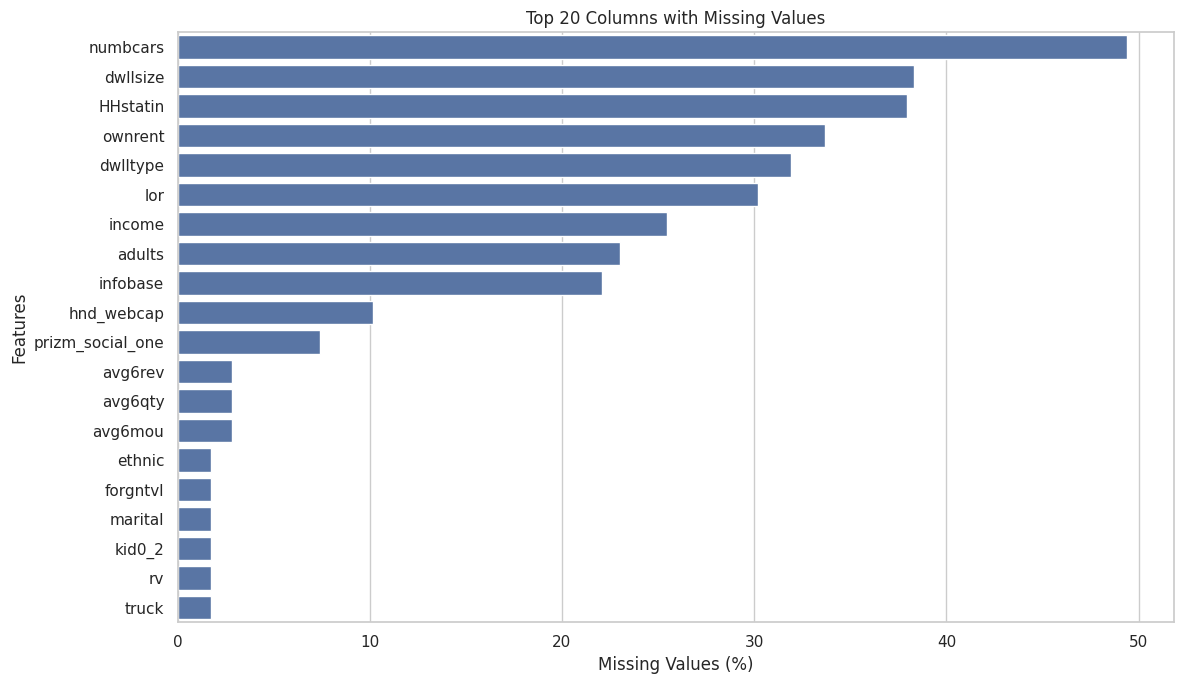

In [10]:

# ==============================================
# PHASE 1 - STEP 5B: MISSING VALUE VISUALIZATION
# ==============================================

if merged is not None:

    top_missing = (
        merged.isnull()
        .mean()
        .mul(100)
        .sort_values(ascending=False)
        .head(20)
    )

    top_missing = top_missing[top_missing > 0]

    plt.figure(figsize=(12, 7))

    sns.barplot(
        x=top_missing.values,
        y=top_missing.index
    )

    plt.title("Top 20 Columns with Missing Values")

    plt.xlabel("Missing Values (%)")
    plt.ylabel("Features")

    plt.tight_layout()
    plt.show()


In [11]:

# ==============================================
# PHASE 1 - STEP 6: UNUSUAL VALUE ANALYSIS
# ==============================================

if merged is not None:

    numeric_columns = merged.select_dtypes(
        include=np.number
    ).columns.tolist()

    negative_results = []

    for column in numeric_columns:

        if column == ID_COL:
            continue

        values = pd.to_numeric(
            merged[column],
            errors="coerce"
        )

        negative_count = (values < 0).sum()

        if negative_count > 0:

            negative_results.append({

                "Feature": column,

                "Negative Count": negative_count,

                "Negative Percentage": round(
                    (negative_count / len(merged)) * 100,
                    2
                ),

                "Minimum Value": values.min()

            })

    negative_report = pd.DataFrame(
        negative_results
    )

    print("NEGATIVE NUMERICAL VALUES")

    if not negative_report.empty:

        display(
            negative_report.sort_values(
                "Negative Count",
                ascending=False
            )
        )

    else:

        print("No negative values found.")

    # Check infinite values
    print("\nINFINITE VALUES")

    infinity_report = {}

    for column in numeric_columns:

        values = pd.to_numeric(
            merged[column],
            errors="coerce"
        )

        infinity_report[column] = np.isinf(values).sum()

    infinity_report = pd.Series(
        infinity_report,
        name="Infinite Count"
    )

    display(
        infinity_report[
            infinity_report > 0
        ].to_frame()
    )

    # Specifically investigate equipment age
    if "eqpdays" in merged.columns:

        print("\nEQUIPMENT AGE VALIDATION")

        print(
            "Minimum equipment age:",
            merged["eqpdays"].min()
        )

        print(
            "Maximum equipment age:",
            merged["eqpdays"].max()
        )

        print(
            "Negative equipment ages:",
            (merged["eqpdays"] < 0).sum()
        )


NEGATIVE NUMERICAL VALUES


,Feature,Negative Count,Negative Percentage,Minimum Value
5,change_rev,56150,56.15,-1107.7400
4,change_mou,53651,53.65,-3875.0000
1,eqpdays,133,0.13,-5.0000
3,totmrc_Mean,23,0.02,-26.9150
2,rev_Mean,5,0.00,-6.1675
0,avg6rev,3,0.00,-2.0000



INFINITE VALUES


,Infinite Count



EQUIPMENT AGE VALIDATION
Minimum equipment age: -5.0
Maximum equipment age: 1823.0
Negative equipment ages: 133


In [12]:

# ==============================================
# PHASE 1 - STEP 6B: OUTLIER DETECTION
# ==============================================

if merged is not None:

    outlier_results = []

    for column in numeric_columns:

        if column in [ID_COL, "churn"]:
            continue

        values = pd.to_numeric(
            merged[column],
            errors="coerce"
        ).replace([np.inf, -np.inf], np.nan).dropna()

        # Skip constant and low-cardinality features
        if values.nunique() <= 10:
            continue

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_count = (
            (values < lower_bound) |
            (values > upper_bound)
        ).sum()

        outlier_results.append({

            "Feature": column,

            "Outlier Count": int(outlier_count),

            "Outlier Percentage": round(
                outlier_count / len(values) * 100,
                2
            ),

            "Lower Bound": lower_bound,

            "Upper Bound": upper_bound

        })

    outlier_report = pd.DataFrame(
        outlier_results
    )

    outlier_report = outlier_report.sort_values(
        "Outlier Percentage",
        ascending=False
    )

    print("TOP 20 FEATURES WITH POTENTIAL OUTLIERS")

    display(outlier_report.head(20))


TOP 20 FEATURES WITH POTENTIAL OUTLIERS


,Feature,Outlier Count,Outlier Percentage,Lower Bound,Upper Bound
32,change_rev,25816,26.05,-20.87625,15.153750
30,roam_Mean,18914,18.98,-0.35250,0.587500
40,plcd_dat_Mean,14980,14.98,0.00000,0.000000
69,callwait_Mean,14305,14.31,-2.00000,3.333333
47,cc_mou_Mean,14265,14.26,-4.31000,7.183333
29,datovr_Mean,13673,13.72,0.00000,0.000000
31,change_mou,13490,13.61,-312.00000,288.000000
46,ccrndmou_Mean,13456,13.46,-6.00000,10.000000
44,comp_dat_Mean,13393,13.39,0.00000,0.000000
51,mou_cdat_Mean,13393,13.39,0.00000,0.000000


CHURN DISTRIBUTION


,Customer Count,Percentage
churn,,
0,50438,50.44
1,49562,49.56


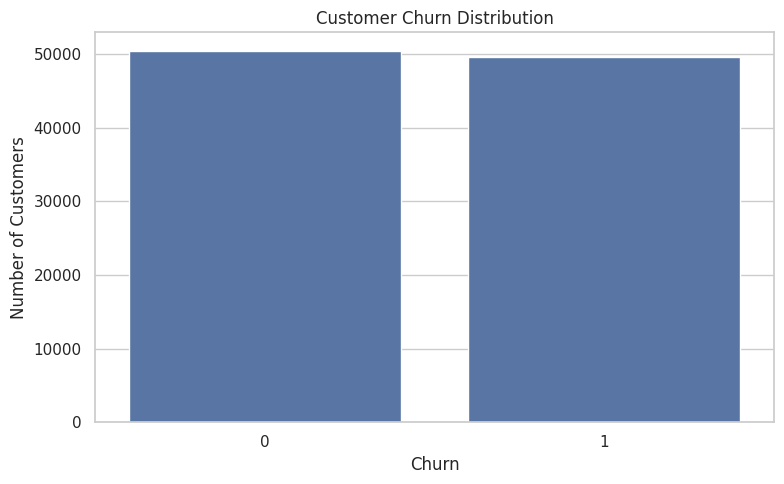

In [13]:

# ==============================================
# PHASE 1 - STEP 7A: CHURN DISTRIBUTION
# ==============================================

if merged is not None:

    print("CHURN DISTRIBUTION")

    churn_counts = merged["churn"].value_counts(
        dropna=False
    ).sort_index()

    churn_percentages = (
        merged["churn"]
        .value_counts(normalize=True, dropna=False)
        .sort_index() * 100
    )

    churn_summary = pd.DataFrame({

        "Customer Count": churn_counts,

        "Percentage": churn_percentages.round(2)

    })

    display(churn_summary)

    # Plot
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=merged,
        x="churn"
    )

    plt.title("Customer Churn Distribution")

    plt.xlabel("Churn")
    plt.ylabel("Number of Customers")

    plt.tight_layout()
    plt.show()


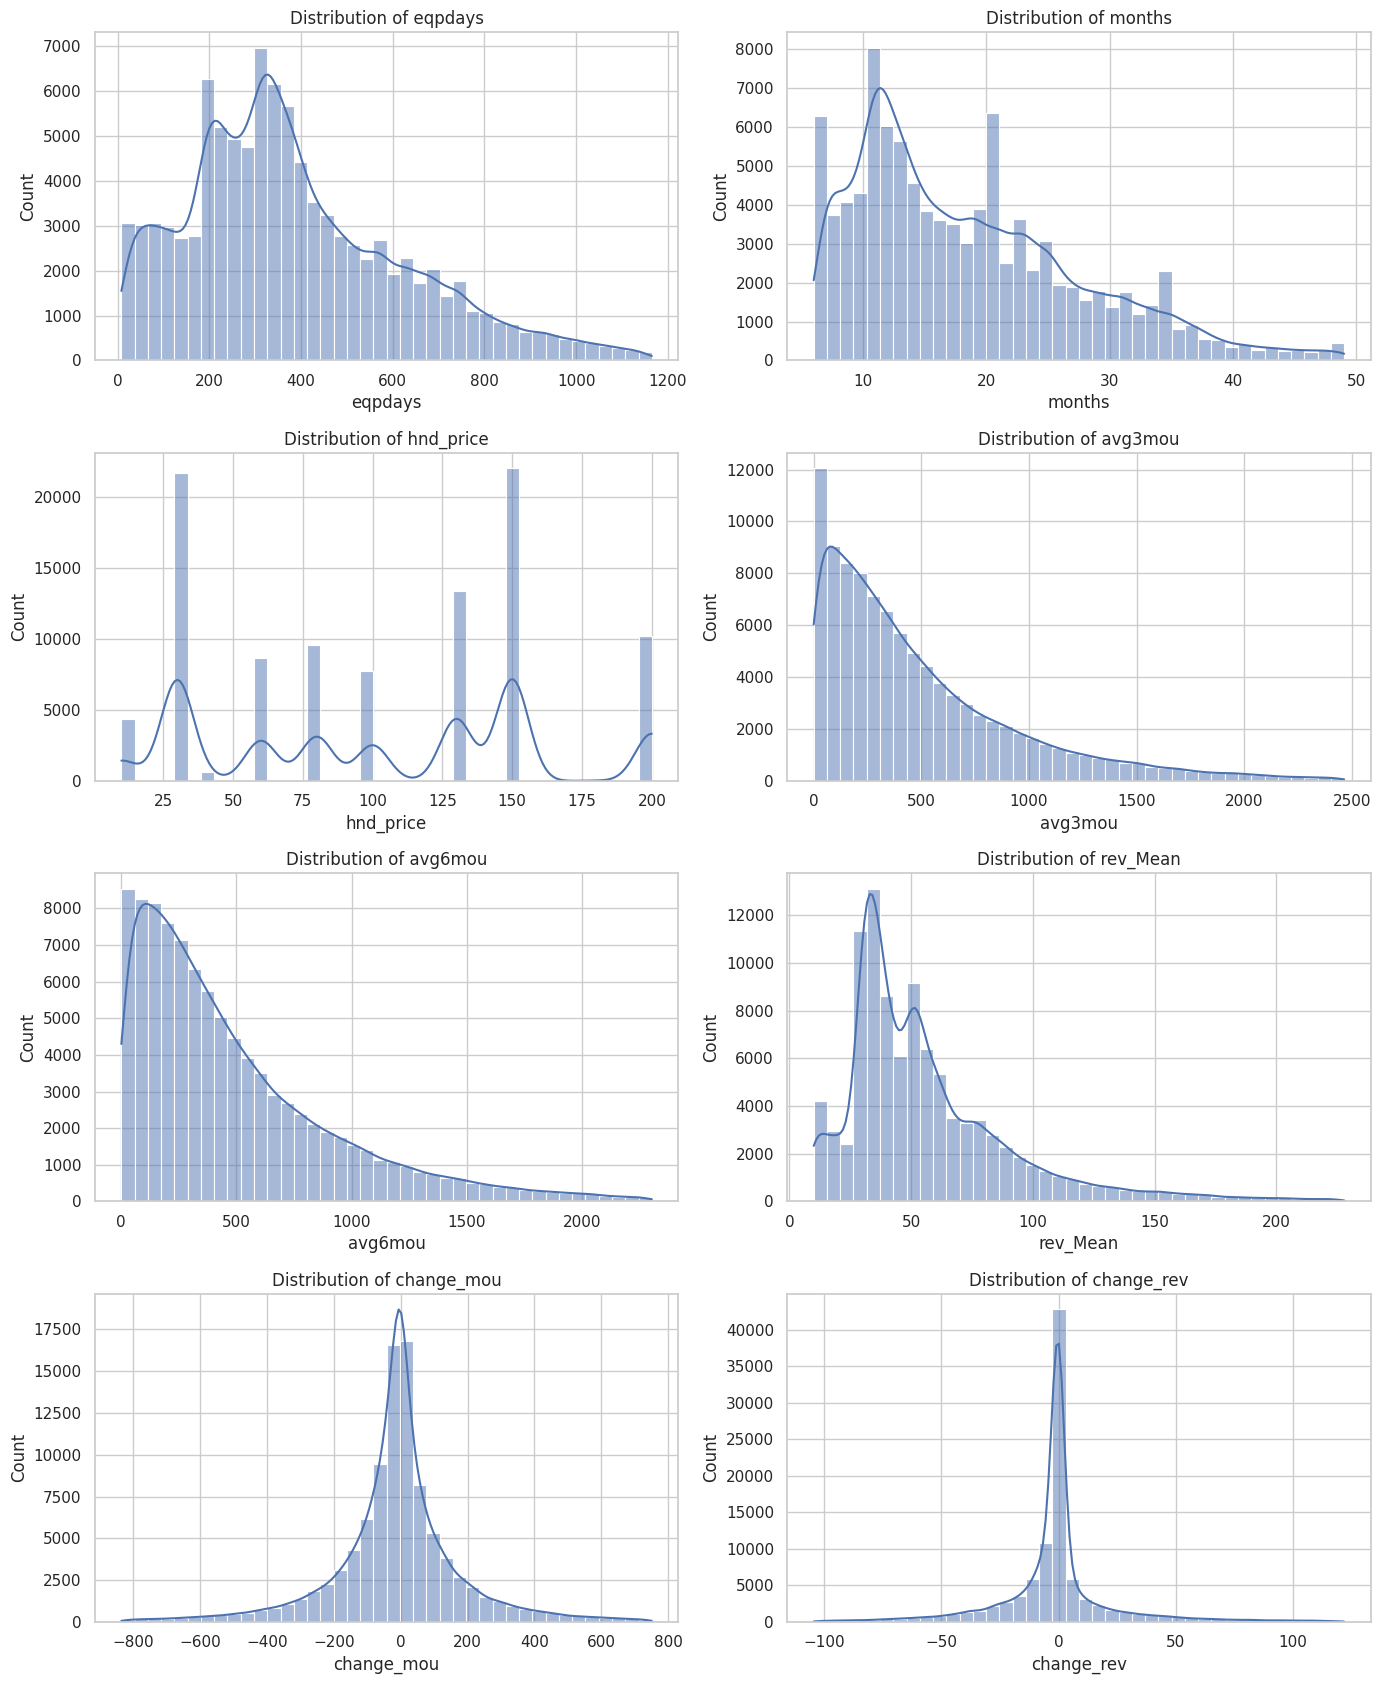

In [14]:

# ==============================================
# PHASE 1 - STEP 7B: NUMERICAL DISTRIBUTIONS
# ==============================================

if merged is not None:

    selected_features = [

        "eqpdays",
        "months",
        "hnd_price",
        "avg3mou",
        "avg6mou",
        "rev_Mean",
        "change_mou",
        "change_rev"

    ]

    selected_features = [
        col for col in selected_features
        if col in merged.columns
    ]

    fig, axes = plt.subplots(
        nrows=4,
        ncols=2,
        figsize=(14, 17)
    )

    axes = axes.flatten()

    for i, column in enumerate(selected_features):

        values = pd.to_numeric(
            merged[column],
            errors="coerce"
        ).replace([np.inf, -np.inf], np.nan).dropna()

        # Remove extreme tails for visualization only
        lower = values.quantile(0.01)
        upper = values.quantile(0.99)

        values = values[
            values.between(lower, upper)
        ]

        sns.histplot(
            values,
            bins=40,
            kde=True,
            ax=axes[i]
        )

        axes[i].set_title(
            f"Distribution of {column}"
        )

        axes[i].set_xlabel(column)

    for j in range(
        len(selected_features),
        len(axes)
    ):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()


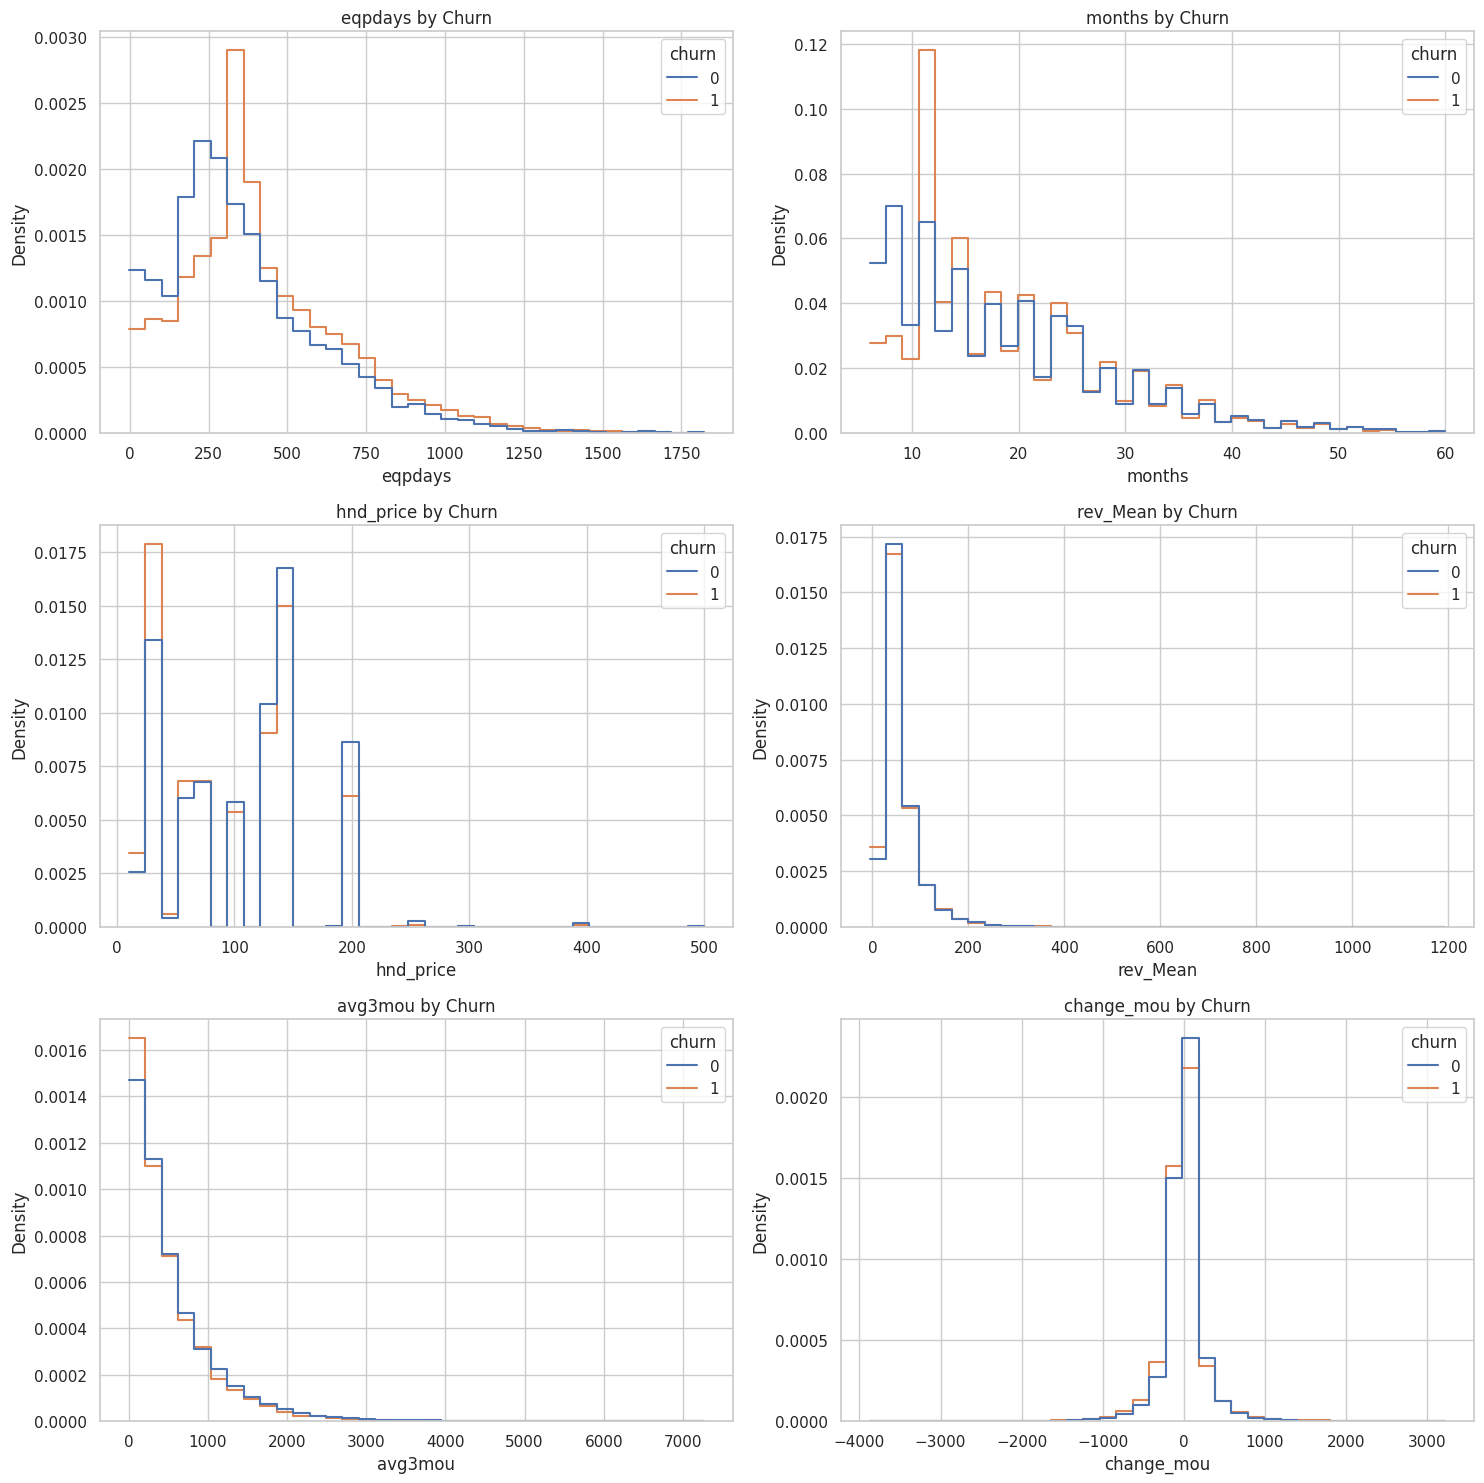

In [15]:

# ==============================================
# PHASE 1 - STEP 7C: DISTRIBUTIONS BY CHURN
# ==============================================

if merged is not None:

    features_to_compare = [

        "eqpdays",
        "months",
        "hnd_price",
        "rev_Mean",
        "avg3mou",
        "change_mou"

    ]

    features_to_compare = [
        col for col in features_to_compare
        if col in merged.columns
    ]

    plot_data = merged[
        features_to_compare + ["churn"]
    ].copy()

    # Remove infinite values
    plot_data = plot_data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    plot_data = plot_data.dropna(
        subset=["churn"]
    )

    # Sample for quicker plotting
    plot_data = plot_data.sample(
        n=min(30000, len(plot_data)),
        random_state=42
    )

    fig, axes = plt.subplots(
        3,
        2,
        figsize=(15, 15)
    )

    axes = axes.flatten()

    for i, column in enumerate(features_to_compare):

        sns.histplot(

            data=plot_data,

            x=column,

            hue="churn",

            bins=35,

            stat="density",

            common_norm=False,

            element="step",

            fill=False,

            ax=axes[i]

        )

        axes[i].set_title(
            f"{column} by Churn"
        )

    for j in range(
        len(features_to_compare),
        len(axes)
    ):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()


In [16]:

# ==============================================
# PHASE 1 - STEP 8: CATEGORICAL ANALYSIS
# ==============================================

if merged is not None:

    categorical_features = [

        "area",
        "dualband",
        "refurb_new",
        "prizm_social_one",
        "ownrent",
        "marital"

    ]

    categorical_features = [
        col for col in categorical_features
        if col in merged.columns
    ]

    churn_numeric = pd.to_numeric(
        merged["churn"],
        errors="coerce"
    )

    if churn_numeric.dropna().isin([0, 1]).all():

        temp = merged.copy()

        temp["_churn_numeric"] = churn_numeric

        for column in categorical_features:

            print(f"\nCHURN ANALYSIS: {column}")

            summary = (
                temp.groupby(
                    column,
                    dropna=False
                )
                .agg(

                    Customers=("_churn_numeric", "size"),

                    Churn_Rate=(
                        "_churn_numeric", "mean"
                    )

                )
                .reset_index()
            )

            summary["Churn_Rate"] = (
                summary["Churn_Rate"] * 100
            ).round(2)

            summary = summary.sort_values(
                "Customers",
                ascending=False
            )

            display(summary.head(20))

    else:

        print(
            "Churn is not encoded as a complete binary "
            "0/1 variable. Inspect its labels before "
            "calculating churn rates."
        )



CHURN ANALYSIS: area


,area,Customers,Churn_Rate
11,NEW YORK CITY AREA,11098,50.03
8,LOS ANGELES AREA,6636,49.82
5,DC/MARYLAND/VIRGINIA AREA,6567,46.03
9,MIDWEST AREA,6346,45.90
17,SOUTHWEST AREA,6187,51.01
0,ATLANTIC SOUTH AREA,6132,48.97
1,CALIFORNIA NORTH AREA,5913,52.11
10,NEW ENGLAND AREA,5452,51.74
4,DALLAS AREA,5426,48.75
3,CHICAGO AREA,5141,49.52



CHURN ANALYSIS: dualband


,dualband,Customers,Churn_Rate
3,Y,72265,48.73
0,N,23196,53.68
1,T,4316,42.19
2,U,222,34.68
4,NaN,1,0.00



CHURN ANALYSIS: refurb_new


,refurb_new,Customers,Churn_Rate
0,N,85593,48.91
1,R,14406,53.44
2,NaN,1,0.00


... (2 outputs left out)


CHURN ANALYSIS: ownrent


,ownrent,Customers,Churn_Rate
0,O,64284,48.72
2,NaN,33706,51.03
1,R,2010,51.94



CHURN ANALYSIS: marital


,marital,Customers,Churn_Rate
4,U,37333,51.27
2,M,31052,48.87
3,S,17627,47.47
1,B,7116,49.69
0,A,5140,48.97
5,NaN,1732,47.86


In [17]:

# ==============================================
# PHASE 1 - STEP 9: GROUP STATISTICS
# ==============================================

if merged is not None:

    important_features = [

        "eqpdays",
        "months",
        "hnd_price",
        "avg3mou",
        "avg6mou",
        "rev_Mean",
        "change_mou",
        "change_rev"

    ]

    important_features = [
        col for col in important_features
        if col in merged.columns
    ]

    numeric_summary = (
        merged.groupby("churn")[important_features]
        .agg(["mean", "median", "std"])
        .round(2)
    )

    print(
        "NUMERICAL FEATURE COMPARISON BY CHURN"
    )

    display(numeric_summary)


NUMERICAL FEATURE COMPARISON BY CHURN


eqpdays                months              hnd_price                 \
         mean median     std   mean median   std      mean  median    std   
churn                                                                       
0      363.28  310.0  249.99  18.63   16.0  9.98    108.13  129.99  61.12   
1      421.09  366.0  259.71  19.04   17.0  9.31     95.54   99.99  60.23   

      avg3mou  ... avg6mou rev_Mean               change_mou                 \
         mean  ...     std     mean median    std       mean median     std   
churn          ...                                                            
0      545.85  ...  513.06    59.22  48.88  44.37      -5.34   -3.0  250.24   
1      492.97  ...  478.59    58.21  47.49  48.17     -22.76  -10.0  300.08   

      change_rev                
            mean median    std  
churn                           
0          -1.41  -0.29  36.00  
1          -0.62  -0.32  61.73  

[2 rows x 24 columns]

In [18]:

# ==============================================
# PHASE 1 - STEP 10: FINAL DATA QUALITY REPORT
# ==============================================

if merged is not None:

    quality_report = pd.DataFrame({

        "Metric": [

            "Client rows",

            "Client columns",

            "Record rows",

            "Record columns",

            "Merged rows",

            "Merged columns",

            "Duplicate Client IDs",

            "Duplicate Record IDs",

            "Missing Client IDs",

            "Missing Record IDs",

            "Duplicate rows in Client",

            "Duplicate rows in Record",

            "Missing churn values",

            "Duplicate rows in merged dataset"

        ],

        "Value": [

            len(client),

            client.shape[1],

            len(record),

            record.shape[1],

            len(merged),

            merged.shape[1],

            client_duplicate_ids,

            record_duplicate_ids,

            client_missing_ids,

            record_missing_ids,

            client.duplicated().sum(),

            record.duplicated().sum(),

            merged["churn"].isnull().sum(),

            merged.duplicated().sum()

        ]

    })

    print("FINAL DATA QUALITY REPORT")

    display(quality_report)

    print("\nFINAL DATASET INFORMATION")

    merged.info()


FINAL DATA QUALITY REPORT


,Metric,Value
0,Client rows,100000
1,Client columns,50
2,Record rows,100000
3,Record columns,51
4,Merged rows,100000
5,Merged columns,100
6,Duplicate Client IDs,0
7,Duplicate Record IDs,0
8,Missing Client IDs,0
9,Missing Record IDs,0



FINAL DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 100 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  object 
 3   crclscod          100000 non-null  object 
 4   asl_flag          100000 non-null  object 
 5   totcalls          100000 non-null  int64  
 6   totmou            100000 non-null  float64
 7   totrev            100000 non-null  float64
 8   adjrev            100000 non-null  float64
 9   adjmou            100000 non-null  float64
 10  adjqty            100000 non-null  int64  
 11  avgrev            100000 non-null  float64
 12  avgmou            100000 non-null  float64
 13  avgqty            100000 non-null  float64
 14  avg3mou           100000 non-null  int64  
 15  avg3qty           100000 non-null  int64 

In [19]:

# ==============================================
# PHASE 1 - STEP 11: SAVE OUTPUTS
# ==============================================

if merged is not None:

    OUTPUT_DIR = Path("/content/phase1_outputs")

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    # Save merged data in compressed CSV format
    merged.to_csv(

        OUTPUT_DIR / "merged_dataset.csv.gz",

        index=False,

        compression="gzip"

    )

    # Save audit reports
    client_missing.to_csv(
        OUTPUT_DIR / "client_missingness.csv",
        index=False
    )

    record_missing.to_csv(
        OUTPUT_DIR / "record_missingness.csv",
        index=False
    )

    quality_report.to_csv(
        OUTPUT_DIR / "data_quality_report.csv",
        index=False
    )

    if not negative_report.empty:

        negative_report.to_csv(
            OUTPUT_DIR / "negative_values_report.csv",
            index=False
        )

    outlier_report.to_csv(
        OUTPUT_DIR / "outlier_report.csv",
        index=False
    )

    print("PHASE 1 OUTPUTS SAVED SUCCESSFULLY!")

    print("\nOutput location:")
    print(OUTPUT_DIR)

    print("\nSaved files:")
    print(os.listdir(OUTPUT_DIR))


PHASE 1 OUTPUTS SAVED SUCCESSFULLY!

Output location:
/content/phase1_outputs

Saved files:
['negative_values_report.csv', 'data_quality_report.csv', 'outlier_report.csv', 'merged_dataset.csv.gz', 'client_missingness.csv', 'record_missingness.csv']


## Exploratory Data Analysis
**Objective**: Investigate customer churn, equipment lifecycle, usage, revenue, service behaviour and geographical segments to identify evidence-backed business hypotheses.

In [20]:

# =====================================================
# PHASE 2 - STEP 1: ANALYSIS SETUP
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import (
    mannwhitneyu,
    ttest_ind,
    chi2_contingency,
    spearmanr
)

sns.set_theme(style="whitegrid")

# Ensure Phase 1 has been completed
if merged is None:
    raise ValueError(
        "The merged dataset is unavailable. "
        "Please run Phase 1 first."
    )

# Work on a separate copy
phase2_df = merged.copy()

# Convert churn to numeric 0/1
phase2_df["churn"] = pd.to_numeric(
    phase2_df["churn"],
    errors="coerce"
)

phase2_df = phase2_df.dropna(
    subset=["churn"]
).copy()

# Validate target
if not set(phase2_df["churn"].unique()).issubset({0, 1}):
    raise ValueError(
        "Unexpected churn values. Inspect the target column."
    )

phase2_df["churn"] = phase2_df["churn"].astype(int)

print("PHASE 2 DATASET READY")

print("Rows:", phase2_df.shape[0])
print("Columns:", phase2_df.shape[1])

print("\nChurn values:")
print(phase2_df["churn"].value_counts())


PHASE 2 DATASET READY
Rows: 100000
Columns: 100

Churn values:
churn
0    50438
1    49562
Name: count, dtype: int64


In [21]:

# =====================================================
# PHASE 2 - STEP 2: NUMERICAL FEATURE COMPARISON
# =====================================================

numeric_features = [

    # Equipment and customer lifecycle
    "eqpdays",
    "months",
    "hnd_price",

    # Recent customer averages
    "avg3mou",
    "avg6mou",
    "avg3rev",
    "avg6rev",

    # Overall revenue and usage
    "mou_Mean",
    "rev_Mean",
    "totmrc_Mean",
    "ovrrev_Mean",

    # Changes in customer behaviour
    "change_mou",
    "change_rev",

    # Network and usage behaviour
    "roam_Mean",
    "drop_vce_Mean",
    "drop_blk_Mean",
    "unan_vce_Mean",

    # Customer support
    "custcare_Mean",
    "cc_mou_Mean",
    "ccrndmou_Mean"

]

# Keep only features present in our dataset
numeric_features = [
    col for col in numeric_features
    if col in phase2_df.columns
]

comparison_results = []

for feature in numeric_features:

    stay = pd.to_numeric(
        phase2_df.loc[
            phase2_df["churn"] == 0, feature
        ],
        errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()

    churn = pd.to_numeric(
        phase2_df.loc[
            phase2_df["churn"] == 1, feature
        ],
        errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()

    if len(stay) < 2 or len(churn) < 2:
        continue

    # Welch's t-test
    t_stat, t_p = ttest_ind(
        stay,
        churn,
        equal_var=False
    )

    # Mann-Whitney U test
    mw_stat, mw_p = mannwhitneyu(
        stay,
        churn,
        alternative="two-sided"
    )

    # Standardised mean difference
    pooled_std = np.sqrt(
        (stay.var() + churn.var()) / 2
    )

    smd = (
        (churn.mean() - stay.mean()) / pooled_std
        if pooled_std > 0 else np.nan
    )

    comparison_results.append({

        "Feature": feature,

        "Stay_N": len(stay),

        "Churn_N": len(churn),

        "Stay_Mean": stay.mean(),

        "Churn_Mean": churn.mean(),

        "Mean_Difference": churn.mean() - stay.mean(),

        "Stay_Median": stay.median(),

        "Churn_Median": churn.median(),

        "Median_Difference": churn.median() - stay.median(),

        "Stay_Std": stay.std(),

        "Churn_Std": churn.std(),

        "SMD": smd,

        "Welch_P_Value": t_p,

        "Mann_Whitney_P_Value": mw_p

    })

numeric_comparison = pd.DataFrame(
    comparison_results
)

# Print all columns without truncation
with pd.option_context(
    "display.max_columns", None,
    "display.width", 300,
    "display.max_rows", 100,
    "display.float_format", "{:,.4f}".format
):

    display(
        numeric_comparison.sort_values(
            "SMD",
            key=lambda x: x.abs(),
            ascending=False
        )
    )


,Feature,Stay_N,Churn_N,Stay_Mean,Churn_Mean,Mean_Difference,Stay_Median,Churn_Median,Median_Difference,Stay_Std,Churn_Std,SMD,Welch_P_Value,Mann_Whitney_P_Value
0,eqpdays,50437,49562,363.2809,421.0895,57.8086,310.0000,366.0000,56.0000,249.9861,259.7056,0.2268,0.0000,0.0000
2,hnd_price,49902,49251,108.1293,95.5395,-12.5898,129.9900,99.9900,-30.0000,61.1232,60.2283,-0.2075,0.0000,0.0000
9,totmrc_Mean,50326,49317,47.7824,44.5431,-3.2393,44.9900,43.4175,-1.5725,24.2631,22.8369,-0.1375,0.0000,0.0000
7,mou_Mean,50326,49317,543.2069,483.3064,-59.9005,380.5000,329.7500,-50.7500,540.3109,507.4747,-0.1143,0.0000,0.0000
3,avg3mou,50438,49562,545.8501,492.9691,-52.8810,380.0000,336.0000,-44.0000,549.2707,515.8762,-0.0992,0.0000,0.0000
4,avg6mou,48741,48420,531.4451,487.6795,-43.7657,379.0000,346.0000,-33.0000,513.0601,478.5948,-0.0882,0.0000,0.0000
19,ccrndmou_Mean,50438,49562,5.1462,4.1791,-0.9671,0.0000,0.0000,0.0000,13.4924,11.9534,-0.0759,0.0000,0.0000
17,custcare_Mean,50438,49562,1.9826,1.5957,-0.3869,0.0000,0.0000,0.0000,5.4658,5.1509,-0.0729,0.0000,0.0000
16,unan_vce_Mean,50438,49562,29.1370,26.4089,-2.7282,16.6667,14.6667,-2.0000,39.3865,37.2337,-0.0712,0.0000,0.0000
18,cc_mou_Mean,50438,49562,4.0516,3.3085,-0.7431,0.0000,0.0000,0.0000,11.1094,9.9131,-0.0706,0.0000,0.0000


In [22]:

# =====================================================
# PHASE 2 - STEP 3A: EQUIPMENT LIFECYCLE ANALYSIS
# =====================================================

equipment_data = phase2_df.copy()

equipment_data["eqpdays"] = pd.to_numeric(
    equipment_data["eqpdays"],
    errors="coerce"
)

# Preserve negative ages as a separate investigation group
age_bins = [

    -np.inf,
    0,
    90,
    180,
    270,
    365,
    450,
    540,
    720,
    np.inf

]

age_labels = [

    "≤0 (Review)",
    "1-90",
    "91-180",
    "181-270",
    "271-365",
    "366-450",
    "451-540",
    "541-720",
    ">720"

]

equipment_data["Equipment_Age_Group"] = pd.cut(

    equipment_data["eqpdays"],

    bins=age_bins,

    labels=age_labels

)

print("EQUIPMENT AGE GROUP COUNTS")

display(
    equipment_data[
        "Equipment_Age_Group"
    ].value_counts(
        sort=False,
        dropna=False
    ).to_frame("Customers")
)


EQUIPMENT AGE GROUP COUNTS


,Customers
Equipment_Age_Group,
≤0 (Review),166
1-90,9489
91-180,8672
181-270,16854
271-365,19502
366-450,12582
451-540,8556
541-720,12882
>720,11296


In [23]:

# =====================================================
# PHASE 2 - STEP 3B: CHURN RATES WITH CONFIDENCE INTERVALS
# =====================================================

def wilson_interval(successes, total, z=1.96):

    if total == 0:
        return np.nan, np.nan

    p = successes / total

    denominator = 1 + (z**2 / total)

    center = (
        p + z**2 / (2 * total)
    ) / denominator

    margin = (
        z * np.sqrt(
            (p * (1 - p) / total)
            + (z**2 / (4 * total**2))
        )
    ) / denominator

    return center - margin, center + margin


age_results = []

for group in age_labels:

    subset = equipment_data[
        equipment_data["Equipment_Age_Group"] == group
    ]

    n = len(subset)
    churn_count = subset["churn"].sum()

    if n == 0:
        continue

    rate = churn_count / n

    lower, upper = wilson_interval(
        churn_count,
        n
    )

    age_results.append({

        "Equipment_Age": group,

        "Customers": n,

        "Churned": int(churn_count),

        "Churn_Rate": rate * 100,

        "CI_Lower": lower * 100,

        "CI_Upper": upper * 100

    })

equipment_summary = pd.DataFrame(age_results)

print("CHURN RATE BY EQUIPMENT AGE")

display(
    equipment_summary.round(2)
)


CHURN RATE BY EQUIPMENT AGE


,Equipment_Age,Customers,Churned,Churn_Rate,CI_Lower,CI_Upper
0,≤0 (Review),166,56,33.73,26.98,41.22
1,1-90,9489,3793,39.97,38.99,40.96
2,91-180,8672,3800,43.82,42.78,44.87
3,181-270,16854,6334,37.58,36.85,38.32
4,271-365,19502,10743,55.09,54.39,55.78
5,366-450,12582,6816,54.17,53.30,55.04
6,451-540,8556,4537,53.03,51.97,54.08
7,541-720,12882,6965,54.07,53.21,54.93
8,>720,11296,6518,57.70,56.79,58.61


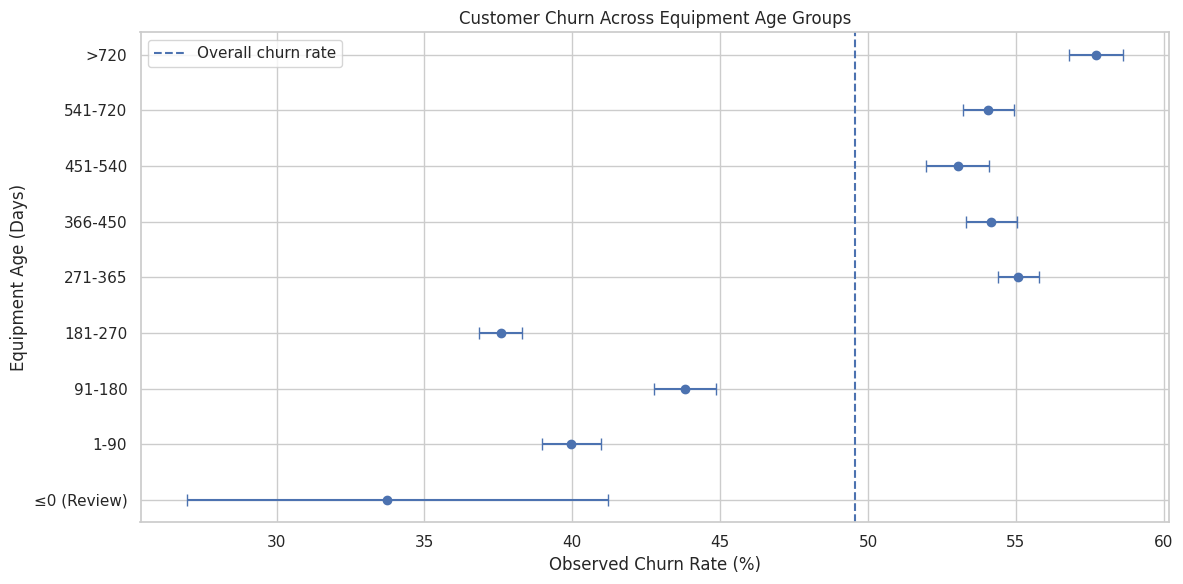

In [24]:

# =====================================================
# PHASE 2 - STEP 3C: EQUIPMENT AGE VISUALIZATION
# =====================================================

plot_age = equipment_summary.copy()

plt.figure(figsize=(12, 6))

plt.errorbar(

    x=plot_age["Churn_Rate"],

    y=plot_age["Equipment_Age"],

    xerr=[

        plot_age["Churn_Rate"] - plot_age["CI_Lower"],

        plot_age["CI_Upper"] - plot_age["Churn_Rate"]

    ],

    fmt="o",

    capsize=4

)

plt.axvline(

    phase2_df["churn"].mean() * 100,

    linestyle="--",

    label="Overall churn rate"

)

plt.title(
    "Customer Churn Across Equipment Age Groups"
)

plt.xlabel("Observed Churn Rate (%)")

plt.ylabel("Equipment Age (Days)")

plt.legend()

plt.tight_layout()

plt.show()


In [25]:

# =====================================================
# PHASE 2 - STEP 3D: EQUIPMENT AGE STATISTICAL TEST
# =====================================================

# Exclude negative equipment ages from this particular
# trend test because their validity needs investigation.

valid_equipment = equipment_data[
    equipment_data["eqpdays"] > 0
].copy()

age_crosstab = pd.crosstab(

    valid_equipment["Equipment_Age_Group"],

    valid_equipment["churn"]

)

# Remove empty groups
age_crosstab = age_crosstab[
    age_crosstab.sum(axis=1) > 0
]

chi2, p_value, dof, expected = chi2_contingency(
    age_crosstab
)

n = age_crosstab.values.sum()

cramers_v = np.sqrt(

    chi2 / (
        n * min(
            age_crosstab.shape[0] - 1,
            age_crosstab.shape[1] - 1
        )
    )

)

rho, spearman_p = spearmanr(

    valid_equipment["eqpdays"],

    valid_equipment["churn"]

)

print("EQUIPMENT AGE STATISTICAL RESULTS")

print("Chi-square statistic:", chi2)

print("Chi-square p-value:", p_value)

print("Cramer's V:", cramers_v)

print("\nSpearman correlation:", rho)

print("Spearman p-value:", spearman_p)


EQUIPMENT AGE STATISTICAL RESULTS
Chi-square statistic: 2221.335434445725
Chi-square p-value: 0.0
Cramer's V: 0.14916605746840453

Spearman correlation: 0.12763821356050858
Spearman p-value: 0.0


In [26]:

# =====================================================
# PHASE 2 - STEP 4A: BEHAVIOURAL FEATURE ENGINEERING
# =====================================================

# These are investigative features only.
# We are not modifying the original dataset.

if (
    "avg3mou" in phase2_df.columns
    and "avg6mou" in phase2_df.columns
):

    phase2_df["recent_usage_difference"] = (

        pd.to_numeric(
            phase2_df["avg3mou"],
            errors="coerce"
        )

        -

        pd.to_numeric(
            phase2_df["avg6mou"],
            errors="coerce"
        )

    )


if (
    "avg3rev" in phase2_df.columns
    and "avg6rev" in phase2_df.columns
):

    phase2_df["recent_revenue_difference"] = (

        pd.to_numeric(
            phase2_df["avg3rev"],
            errors="coerce"
        )

        -

        pd.to_numeric(
            phase2_df["avg6rev"],
            errors="coerce"
        )

    )


trend_features = [

    col for col in [

        "recent_usage_difference",

        "recent_revenue_difference"

    ]

    if col in phase2_df.columns

]

print("RECENT BEHAVIOURAL CHANGE FEATURES")

display(
    phase2_df[trend_features + ["churn"]].head()
)


RECENT BEHAVIOURAL CHANGE FEATURES


,recent_usage_difference,recent_revenue_difference,churn
0,-50.0,-8.0,1
1,-172.0,-8.0,0
2,1.0,0.0,1
3,-42.0,-2.0,0
4,-28.0,-25.0,0


In [27]:

# =====================================================
# PHASE 2 - STEP 4B: QUINTILE CHURN ANALYSIS
# =====================================================

def quantile_churn_analysis(data, feature, q=5):

    temp = data[[feature, "churn"]].copy()

    temp[feature] = pd.to_numeric(
        temp[feature],
        errors="coerce"
    )

    temp[feature] = temp[feature].replace(
        [np.inf, -np.inf],
        np.nan
    )

    temp = temp.dropna(
        subset=[feature, "churn"]
    )

    if temp[feature].nunique() < 2:
        return pd.DataFrame()

    temp["Quantile"] = pd.qcut(

        temp[feature],

        q=q,

        labels=False,

        duplicates="drop"

    )

    results = []

    for group, subset in temp.groupby(
        "Quantile",
        observed=True
    ):

        n = len(subset)

        churned = int(subset["churn"].sum())

        rate = churned / n

        lower, upper = wilson_interval(
            churned,
            n
        )

        results.append({

            "Feature": feature,

            "Quantile": f"Q{int(group) + 1}",

            "Customers": n,

            "Minimum": subset[feature].min(),

            "Maximum": subset[feature].max(),

            "Median": subset[feature].median(),

            "Churn_Rate": rate * 100,

            "CI_Lower": lower * 100,

            "CI_Upper": upper * 100

        })

    return pd.DataFrame(results)


# Behavioural features
usage_features = [

    "avg3mou",
    "avg6mou",
    "mou_Mean",
    "change_mou",
    "recent_usage_difference",
    "roam_Mean",
    "drop_vce_Mean",
    "drop_blk_Mean",
    "unan_vce_Mean",
    "custcare_Mean",
    "cc_mou_Mean",
    "attempt_Mean",
    "complete_Mean"

]

usage_features = [

    col for col in usage_features

    if col in phase2_df.columns

]

usage_results = []

for feature in usage_features:

    result = quantile_churn_analysis(
        phase2_df,
        feature
    )

    if not result.empty:
        usage_results.append(result)


usage_quantile_report = pd.concat(
    usage_results,
    ignore_index=True
)

print("USAGE AND CUSTOMER ENGAGEMENT: CHURN BY QUINTILE")

display(
    usage_quantile_report.round(3)
)


USAGE AND CUSTOMER ENGAGEMENT: CHURN BY QUINTILE


,Feature,Quantile,Customers,Minimum,Maximum,Median,Churn_Rate,CI_Lower,CI_Upper
0,avg3mou,Q1,20091,0.000,116.000,49.000,54.706,54.017,55.393
1,avg3mou,Q2,20007,117.000,267.000,189.000,50.117,49.425,50.810
2,avg3mou,Q3,19913,268.000,469.000,358.000,48.782,48.088,49.477
3,avg3mou,Q4,20024,470.000,831.000,615.000,47.828,47.136,48.520
4,avg3mou,Q5,19965,832.000,7716.000,1201.000,46.346,45.655,47.038
5,avg6mou,Q1,19451,0.000,128.000,61.000,53.277,52.576,53.978
6,avg6mou,Q2,19518,129.000,275.000,199.000,50.856,50.154,51.557
7,avg6mou,Q3,19367,276.000,469.000,363.000,49.471,48.767,50.175
8,avg6mou,Q4,19411,470.000,809.000,608.000,49.065,48.362,49.768
9,avg6mou,Q5,19414,810.000,7217.000,1149.000,46.492,45.791,47.194


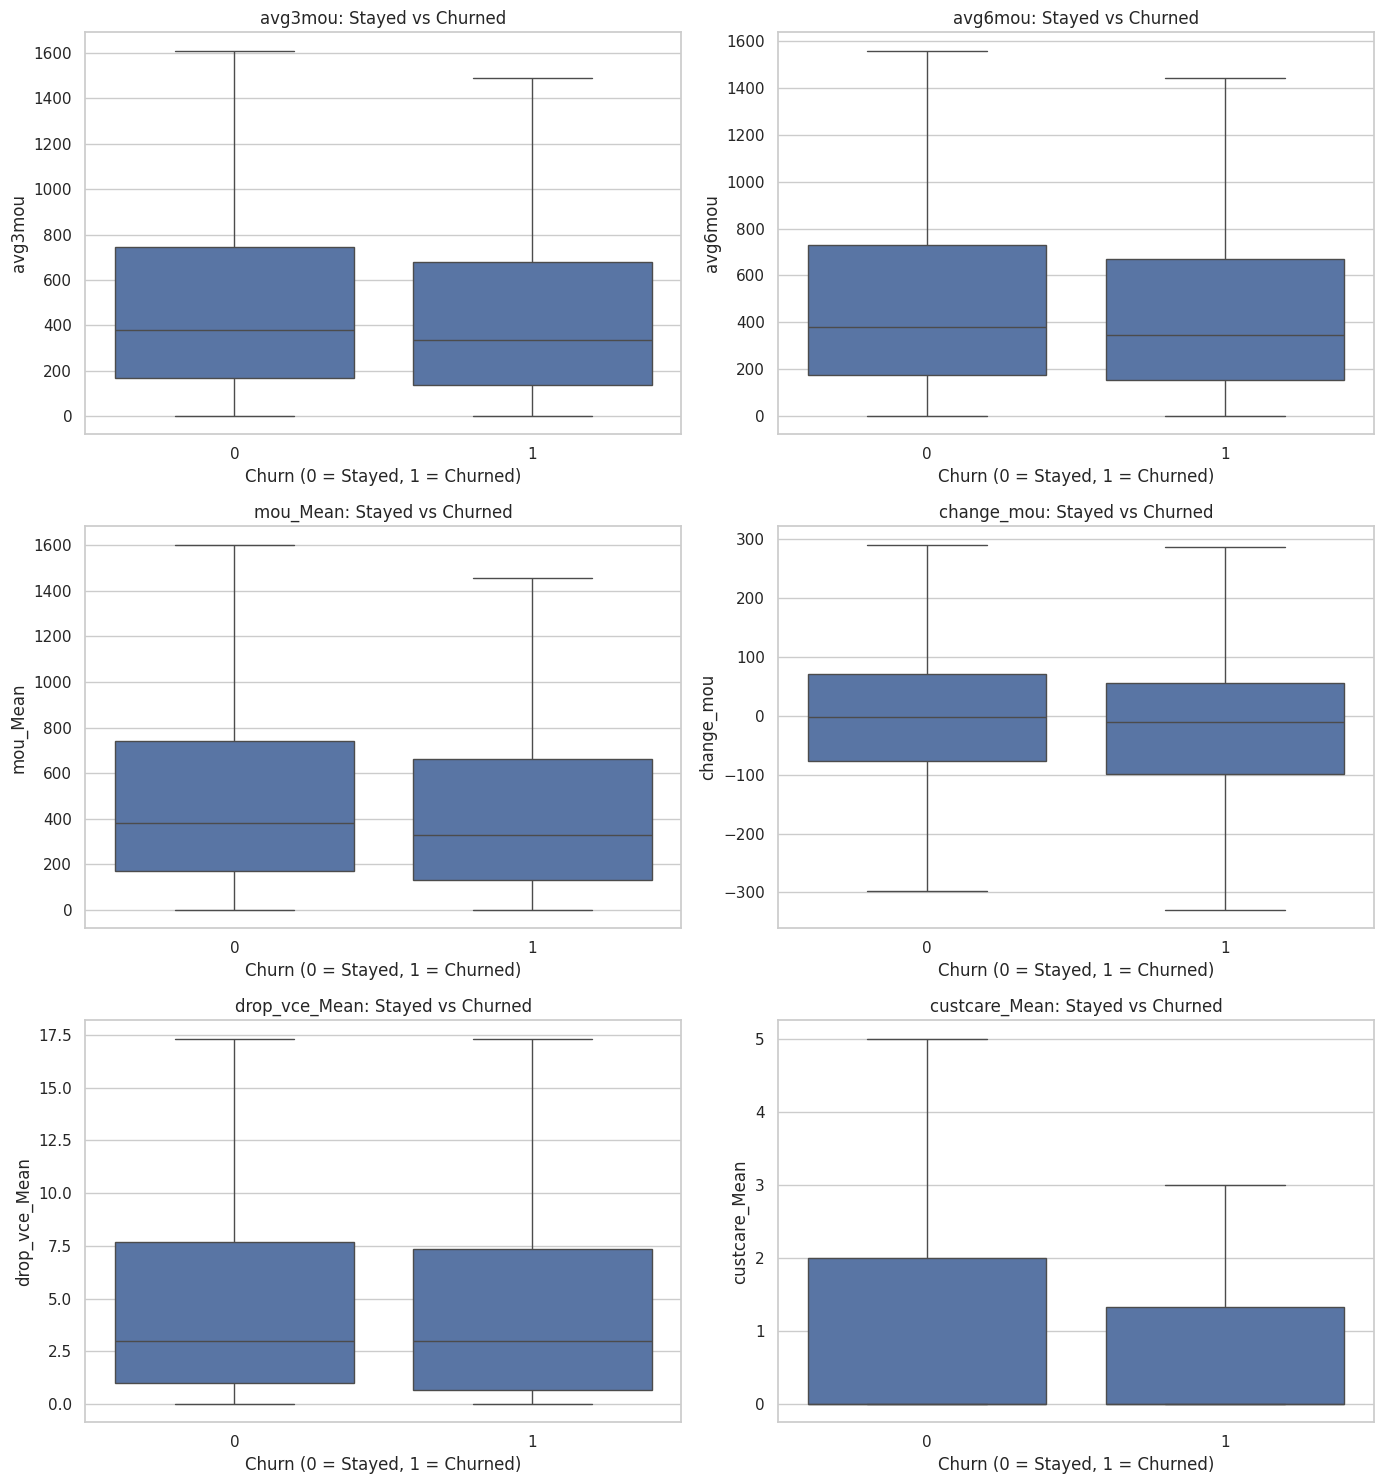

In [28]:

# =====================================================
# PHASE 2 - STEP 4C: USAGE DISTRIBUTION VISUALIZATION
# =====================================================

plot_features = [

    "avg3mou",

    "avg6mou",

    "mou_Mean",

    "change_mou",

    "drop_vce_Mean",

    "custcare_Mean"

]

plot_features = [

    col for col in plot_features

    if col in phase2_df.columns

]

fig, axes = plt.subplots(

    nrows=3,

    ncols=2,

    figsize=(14, 15)

)

axes = axes.flatten()

for i, feature in enumerate(plot_features):

    sns.boxplot(

        data=phase2_df,

        x="churn",

        y=feature,

        showfliers=False,

        ax=axes[i]

    )

    axes[i].set_title(
        f"{feature}: Stayed vs Churned"
    )

    axes[i].set_xlabel(
        "Churn (0 = Stayed, 1 = Churned)"
    )

for j in range(
    len(plot_features),
    len(axes)
):

    axes[j].set_visible(False)

plt.tight_layout()

plt.show()


In [29]:

# =====================================================
# PHASE 2 - STEP 5: REVENUE ANALYSIS
# =====================================================

revenue_features = [

    "rev_Mean",

    "totmrc_Mean",

    "ovrrev_Mean",

    "vceovr_Mean",

    "datovr_Mean",

    "change_rev",

    "avg3rev",

    "avg6rev",

    "recent_revenue_difference"

]

revenue_features = [

    col for col in revenue_features

    if col in phase2_df.columns

]

revenue_results = []

for feature in revenue_features:

    result = quantile_churn_analysis(

        phase2_df,

        feature

    )

    if not result.empty:

        revenue_results.append(result)


revenue_quantile_report = pd.concat(

    revenue_results,

    ignore_index=True

)

print("REVENUE AND BILLING: CHURN BY QUINTILE")

display(
    revenue_quantile_report.round(3)
)


REVENUE AND BILLING: CHURN BY QUINTILE


,Feature,Quantile,Customers,Minimum,Maximum,Median,Churn_Rate,CI_Lower,CI_Upper
0,rev_Mean,Q1,19932,-6.168,30.852,25.086,52.885,52.191,53.577
1,rev_Mean,Q2,19933,30.855,40.040,35.170,48.994,48.300,49.688
2,rev_Mean,Q3,19923,40.042,54.095,48.202,48.477,47.783,49.171
3,rev_Mean,Q4,19926,54.098,78.828,63.400,48.640,47.946,49.334
4,rev_Mean,Q5,19929,78.832,3843.262,103.982,48.472,47.779,49.166
5,totmrc_Mean,Q1,22946,-26.915,29.990,21.768,55.208,54.564,55.850
6,totmrc_Mean,Q2,20746,29.992,39.990,34.990,52.058,51.378,52.738
7,totmrc_Mean,Q3,16095,39.992,47.005,44.990,45.374,44.606,46.145
8,totmrc_Mean,Q4,22135,47.008,59.990,54.980,48.850,48.192,49.509
9,totmrc_Mean,Q5,17721,59.992,409.990,75.000,43.637,42.909,44.369


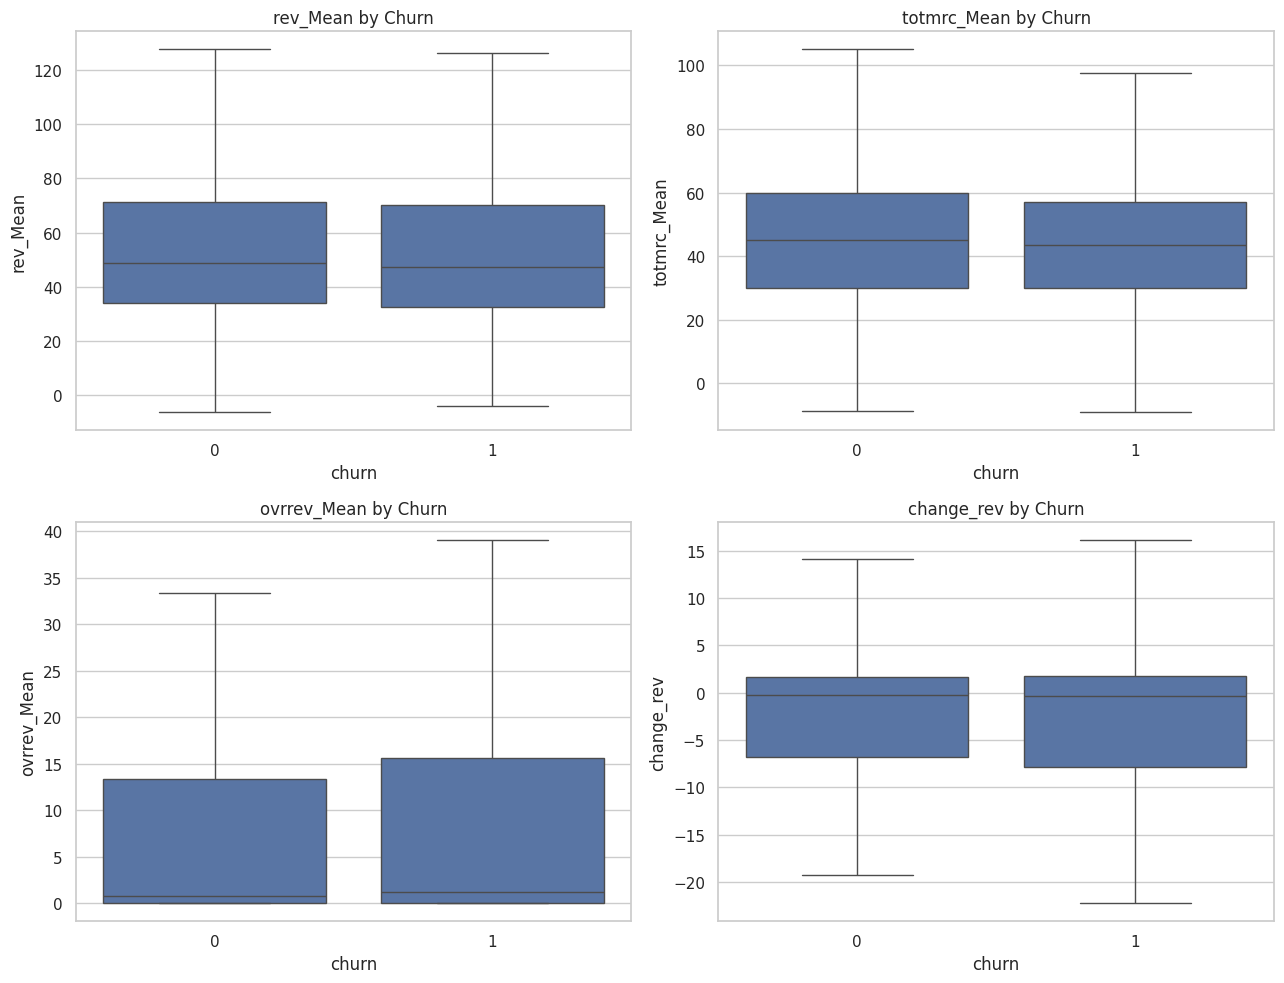

In [30]:

# =====================================================
# PHASE 2 - STEP 5B: REVENUE VISUALIZATION
# =====================================================

selected_revenue = [

    "rev_Mean",

    "totmrc_Mean",

    "ovrrev_Mean",

    "change_rev"

]

selected_revenue = [

    col for col in selected_revenue

    if col in phase2_df.columns

]

fig, axes = plt.subplots(

    2,

    2,

    figsize=(13, 10)

)

axes = axes.flatten()

for i, feature in enumerate(selected_revenue):

    sns.boxplot(

        data=phase2_df,

        x="churn",

        y=feature,

        showfliers=False,

        ax=axes[i]

    )

    axes[i].set_title(
        f"{feature} by Churn"
    )

for j in range(
    len(selected_revenue),
    len(axes)
):

    axes[j].set_visible(False)

plt.tight_layout()

plt.show()


In [31]:

# =====================================================
# PHASE 2 - STEP 6: SERVICE QUALITY ANALYSIS
# =====================================================

service_features = [

    "drop_vce_Mean",

    "drop_dat_Mean",

    "blck_vce_Mean",

    "blck_dat_Mean",

    "drop_blk_Mean",

    "unan_vce_Mean",

    "custcare_Mean",

    "cc_mou_Mean",

    "ccrndmou_Mean",

    "roam_Mean"

]

service_features = [

    col for col in service_features

    if col in phase2_df.columns

]

service_results = []

for feature in service_features:

    result = quantile_churn_analysis(

        phase2_df,

        feature

    )

    if not result.empty:

        service_results.append(result)


service_quantile_report = pd.concat(

    service_results,

    ignore_index=True

)

print("SERVICE QUALITY AND CUSTOMER SUPPORT")

display(
    service_quantile_report.round(3)
)


SERVICE QUALITY AND CUSTOMER SUPPORT


,Feature,Quantile,Customers,Minimum,Maximum,Median,Churn_Rate,CI_Lower,CI_Upper
0,drop_vce_Mean,Q1,20627,0.000,0.333,0.000,52.712,52.031,53.393
1,drop_vce_Mean,Q2,21483,0.667,2.000,1.333,48.327,47.659,48.995
2,drop_vce_Mean,Q3,18645,2.333,4.333,3.333,48.919,48.202,49.637
3,drop_vce_Mean,Q4,20006,4.667,9.333,6.667,49.380,48.688,50.073
4,drop_vce_Mean,Q5,19239,9.500,232.667,15.333,48.376,47.670,49.082
5,drop_dat_Mean,Q1,100000,0.000,207.333,0.000,49.562,49.252,49.872
6,blck_vce_Mean,Q1,46972,0.000,0.667,0.000,50.954,50.502,51.406
7,blck_vce_Mean,Q2,14897,1.000,1.667,1.333,49.017,48.214,49.820
8,blck_vce_Mean,Q3,18359,2.000,4.667,3.000,48.064,47.341,48.787
9,blck_vce_Mean,Q4,19772,5.000,385.333,10.000,48.058,47.362,48.755


In [32]:

# =====================================================
# PHASE 2 - STEP 7: CATEGORICAL SEGMENT ANALYSIS
# =====================================================

def categorical_churn_analysis(data, feature):

    temp = data[[feature, "churn"]].copy()

    temp[feature] = (
        temp[feature]
        .fillna("Missing")
        .astype(str)
    )

    results = []

    for category, subset in temp.groupby(feature):

        n = len(subset)

        churned = int(subset["churn"].sum())

        rate = churned / n

        lower, upper = wilson_interval(
            churned,
            n
        )

        results.append({

            "Feature": feature,

            "Category": category,

            "Customers": n,

            "Churned": churned,

            "Churn_Rate": rate * 100,

            "CI_Lower": lower * 100,

            "CI_Upper": upper * 100

        })

    summary = pd.DataFrame(results)

    # Chi-square test, excluding missing categories
    valid = temp[temp[feature] != "Missing"]

    contingency = pd.crosstab(

        valid[feature],

        valid["churn"]

    )

    # Ignore extremely small groups for the test
    contingency = contingency[
        contingency.sum(axis=1) >= 30
    ]

    if (
        contingency.shape[0] >= 2
        and contingency.shape[1] == 2
    ):

        chi2, p_value, dof, expected = (
            chi2_contingency(contingency)
        )

        n_test = contingency.values.sum()

        cramers_v = np.sqrt(

            chi2 / (

                n_test * min(

                    contingency.shape[0] - 1,

                    contingency.shape[1] - 1

                )

            )

        )

    else:

        chi2 = np.nan
        p_value = np.nan
        cramers_v = np.nan

    return summary, {

        "Feature": feature,

        "Chi_Square": chi2,

        "P_Value": p_value,

        "Cramers_V": cramers_v

    }


categorical_features = [

    "area",

    "dualband",

    "refurb_new",

    "prizm_social_one",

    "ownrent",

    "marital",

    "hnd_webcap"

]

categorical_features = [

    col for col in categorical_features

    if col in phase2_df.columns

]

categorical_results = []

categorical_tests = []

for feature in categorical_features:

    summary, test_result = categorical_churn_analysis(

        phase2_df,

        feature

    )

    categorical_results.append(summary)

    categorical_tests.append(test_result)

    print(f"\nCHURN BY {feature.upper()}")

    display(
        summary.sort_values(
            "Churn_Rate",
            ascending=False
        ).round(3)
    )


categorical_test_report = pd.DataFrame(
    categorical_tests
)

print("\nOVERALL CATEGORICAL ASSOCIATION TESTS")

display(
    categorical_test_report.round(5)
)



CHURN BY AREA


,Feature,Category,Customers,Churned,Churn_Rate,CI_Lower,CI_Upper
10,area,Missing,40,26,65.000,49.506,77.866
14,area,NORTHWEST/ROCKY MOUNTAIN AREA,4328,2463,56.909,55.428,58.377
17,area,SOUTH FLORIDA AREA,3332,1778,53.361,51.665,55.050
1,area,CALIFORNIA NORTH AREA,5913,3081,52.106,50.831,53.377
13,area,NORTH FLORIDA AREA,4350,2262,52.000,50.514,53.482
11,area,NEW ENGLAND AREA,5452,2821,51.742,50.415,53.067
18,area,SOUTHWEST AREA,6187,3156,51.010,49.764,52.255
16,area,PHILADELPHIA AREA,2446,1239,50.654,48.673,52.633
12,area,NEW YORK CITY AREA,11098,5552,50.027,49.097,50.957
8,area,LOS ANGELES AREA,6636,3306,49.819,48.617,51.022



CHURN BY DUALBAND


,Feature,Category,Customers,Churned,Churn_Rate,CI_Lower,CI_Upper
1,dualband,N,23196,12452,53.682,53.039,54.323
4,dualband,Y,72265,35212,48.726,48.362,49.091
2,dualband,T,4316,1821,42.192,40.726,43.672
3,dualband,U,222,77,34.685,28.732,41.158
0,dualband,Missing,1,0,0.000,0.000,79.346



CHURN BY REFURB_NEW


,Feature,Category,Customers,Churned,Churn_Rate,CI_Lower,CI_Upper
2,refurb_new,R,14406,7698,53.436,52.621,54.250
1,refurb_new,N,85593,41864,48.911,48.576,49.245
0,refurb_new,Missing,1,0,0.000,0.000,79.346


... (6 outputs left out)


CHURN BY HND_WEBCAP


,Feature,Category,Customers,Churned,Churn_Rate,CI_Lower,CI_Upper
0,hnd_webcap,Missing,10189,6027,59.152,58.194,60.103
2,hnd_webcap,WC,13843,7794,56.303,55.475,57.127
3,hnd_webcap,WCMB,75733,35655,47.080,46.725,47.436
1,hnd_webcap,UNKW,235,86,36.596,30.698,42.924



OVERALL CATEGORICAL ASSOCIATION TESTS


,Feature,Chi_Square,P_Value,Cramers_V
0,area,269.52404,0.00000,0.05193
1,dualband,291.11528,0.00000,0.05396
2,refurb_new,100.84140,0.00000,0.03176
3,prizm_social_one,43.82059,0.00000,0.02175
4,ownrent,7.96238,0.00478,0.01096
5,marital,81.03961,0.00000,0.02872
6,hnd_webcap,411.90171,0.00000,0.06772


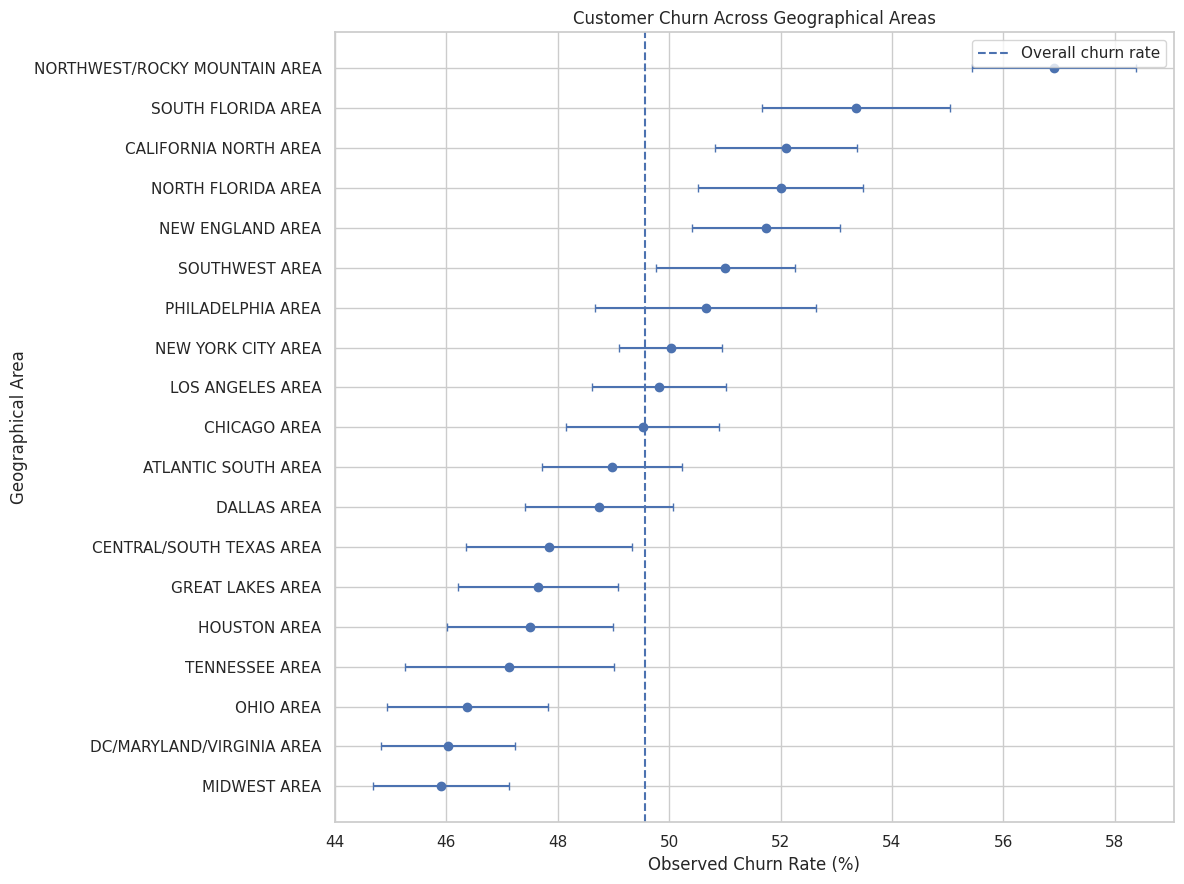

In [33]:

# =====================================================
# PHASE 2 - STEP 7B: GEOGRAPHICAL CHURN VISUALIZATION
# =====================================================

area_summary = next(

    summary for summary in categorical_results

    if summary["Feature"].iloc[0] == "area"

)

# Exclude missing geographical values for the chart
area_plot = area_summary[
    area_summary["Category"] != "Missing"
].sort_values(
    "Churn_Rate",
    ascending=True
)

plt.figure(figsize=(12, 9))

plt.errorbar(

    x=area_plot["Churn_Rate"],

    y=area_plot["Category"],

    xerr=[

        area_plot["Churn_Rate"] - area_plot["CI_Lower"],

        area_plot["CI_Upper"] - area_plot["Churn_Rate"]

    ],

    fmt="o",

    capsize=3

)

plt.axvline(

    phase2_df["churn"].mean() * 100,

    linestyle="--",

    label="Overall churn rate"

)

plt.xlabel("Observed Churn Rate (%)")

plt.ylabel("Geographical Area")

plt.title("Customer Churn Across Geographical Areas")

plt.legend()

plt.tight_layout()

plt.show()


In [35]:

# =====================================================
# PHASE 2 - STEP 9: SAVE ANALYSIS OUTPUTS
# =====================================================

PHASE2_OUTPUT = "/content/phase2_outputs"

os.makedirs(
    PHASE2_OUTPUT,
    exist_ok=True
)

# Numerical comparison
numeric_comparison.to_csv(

    f"{PHASE2_OUTPUT}/numeric_comparison.csv",

    index=False

)

# Equipment lifecycle
equipment_summary.to_csv(

    f"{PHASE2_OUTPUT}/equipment_churn_analysis.csv",

    index=False

)

# Usage
usage_quantile_report.to_csv(

    f"{PHASE2_OUTPUT}/usage_churn_analysis.csv",

    index=False

)

# Revenue
revenue_quantile_report.to_csv(

    f"{PHASE2_OUTPUT}/revenue_churn_analysis.csv",

    index=False

)

# Service quality
service_quantile_report.to_csv(

    f"{PHASE2_OUTPUT}/service_churn_analysis.csv",

    index=False

)

# Categorical
all_categorical = pd.concat(

    categorical_results,

    ignore_index=True

)

all_categorical.to_csv(

    f"{PHASE2_OUTPUT}/categorical_churn_analysis.csv",

    index=False

)

categorical_test_report.to_csv(

    f"{PHASE2_OUTPUT}/categorical_statistical_tests.csv",

    index=False

)

print("PHASE 2 OUTPUTS SAVED SUCCESSFULLY!")

print("\nFiles created:")

print(os.listdir(PHASE2_OUTPUT))


PHASE 2 OUTPUTS SAVED SUCCESSFULLY!

Files created:
['revenue_churn_analysis.csv', 'equipment_churn_analysis.csv', 'service_churn_analysis.csv', 'numeric_comparison.csv', 'categorical_churn_analysis.csv', 'usage_churn_analysis.csv', 'categorical_statistical_tests.csv']


In [37]:

# =====================================================
# PHASE 2 - FINAL VALIDATION (CORRECTED)
# DEVICE INTERACTIONS AND MISSINGNESS
# =====================================================

# IMPORTANT:
# Equipment_Age_Group was created in equipment_data,
# so use equipment_data for equipment-related analysis.

# 1. HND_WEBCAP MISSINGNESS VS CHURN

temp = phase2_df.copy()

temp["webcap_status"] = (
    temp["hnd_webcap"]
    .fillna("Missing")
    .astype(str)
)

print("HND_WEBCAP MISSINGNESS ANALYSIS")

webcap_summary = (
    temp.groupby("webcap_status")
    .agg(
        Customers=("churn", "size"),
        Churned=("churn", "sum"),
        Churn_Rate=("churn", "mean")
    )
    .reset_index()
)

webcap_summary["Churn_Rate"] *= 100

display(webcap_summary.round(2))


# Test missing versus recorded information

temp["webcap_missing"] = (
    temp["hnd_webcap"].isna().astype(int)
)

missing_crosstab = pd.crosstab(
    temp["webcap_missing"],
    temp["churn"]
)

chi2, p, dof, expected = chi2_contingency(
    missing_crosstab
)

print("\nMISSINGNESS VS CHURN")

print("Chi-square:", chi2)
print("P-value:", p)


# 2. EQUIPMENT AGE × REFURBISHED STATUS

print("\nEQUIPMENT AGE × REFURBISHED STATUS")

age_refurb = (
    equipment_data.groupby(
        ["Equipment_Age_Group", "refurb_new"],
        observed=True
    )
    .agg(
        Customers=("churn", "size"),
        Churned=("churn", "sum"),
        Mean_Equipment_Age=("eqpdays", "mean")
    )
    .reset_index()
)

age_refurb["Churn_Rate"] = (
    age_refurb["Churned"]
    / age_refurb["Customers"]
    * 100
)

display(age_refurb.round(2))


# 3. EQUIPMENT AGE × DUALBAND STATUS

print("\nEQUIPMENT AGE × DUALBAND STATUS")

age_dualband = (
    equipment_data.groupby(
        ["Equipment_Age_Group", "dualband"],
        observed=True
    )
    .agg(
        Customers=("churn", "size"),
        Churned=("churn", "sum")
    )
    .reset_index()
)

age_dualband["Churn_Rate"] = (
    age_dualband["Churned"]
    / age_dualband["Customers"]
    * 100
)

display(age_dualband.round(2))

print("\nFINAL PHASE 2 VALIDATION COMPLETED!")


HND_WEBCAP MISSINGNESS ANALYSIS


,webcap_status,Customers,Churned,Churn_Rate
0,Missing,10189,6027,59.15
1,UNKW,235,86,36.60
2,WC,13843,7794,56.30
3,WCMB,75733,35655,47.08



MISSINGNESS VS CHURN
Chi-square: 416.9561727914187
P-value: 1.1219588475821069e-92

EQUIPMENT AGE × REFURBISHED STATUS


,Equipment_Age_Group,refurb_new,Customers,Churned,Mean_Equipment_Age,Churn_Rate
0,≤0 (Review),N,127,38,-1.88,29.92
1,≤0 (Review),R,39,18,-2.10,46.15
2,1-90,N,6853,2529,45.04,36.90
3,1-90,R,2636,1264,46.10,47.95
4,91-180,N,6001,2446,134.31,40.76
5,91-180,R,2671,1354,134.71,50.69
6,181-270,N,14517,5150,223.00,35.48
7,181-270,R,2337,1184,223.03,50.66
8,271-365,N,17239,9432,320.30,54.71
9,271-365,R,2263,1311,316.90,57.93



EQUIPMENT AGE × DUALBAND STATUS


,Equipment_Age_Group,dualband,Customers,Churned,Churn_Rate
0,≤0 (Review),N,59,19,32.20
1,≤0 (Review),T,14,3,21.43
2,≤0 (Review),U,16,6,37.50
3,≤0 (Review),Y,77,28,36.36
4,1-90,N,1749,680,38.88
5,1-90,T,960,377,39.27
6,1-90,U,165,46,27.88
7,1-90,Y,6615,2690,40.67
8,91-180,N,1558,726,46.60
9,91-180,T,751,294,39.15



FINAL PHASE 2 VALIDATION COMPLETED!


## Feature Engineering and Data Preprocessing
**Objective:** Convert the original customer information into a reliable, model-ready dataset without losing valuable information or introducing data leakage.

My tasks:
1. Handle missing numerical and categorical values.
2. Investigate the 133 negative equipment-age records and other unusual values.
3. Create missingness indicators where justified.
4. Engineer equipment-age and customer-engagement features.
5. Prepare categorical and numerical preprocessing pipelines.
6. Separate training and testing data correctly.
7. Establish a reproducible model-ready dataset.

In [38]:

# =====================================================
# PHASE 3 - STEP 1: DATASET INITIALIZATION
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder

from sklearn.impute import SimpleImputer

from sklearn.base import clone

import os
import joblib

# Use the original merged dataset
model_df = merged.copy()

# Validate target
model_df["churn"] = pd.to_numeric(
    model_df["churn"],
    errors="coerce"
)

model_df = model_df.dropna(
    subset=["churn"]
).copy()

model_df = model_df[
    model_df["churn"].isin([0, 1])
].copy()

model_df["churn"] = model_df["churn"].astype(int)

# Clean categorical text
categorical_raw = model_df.select_dtypes(
    include=["object", "string"]
).columns

for col in categorical_raw:

    model_df[col] = (
        model_df[col]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

# Replace infinite numerical values with missing values
numeric_raw = model_df.select_dtypes(
    include=np.number
).columns

model_df[numeric_raw] = model_df[
    numeric_raw
].replace(
    [np.inf, -np.inf],
    np.nan
)

print("PHASE 3 DATASET INITIALIZED")

print("Rows:", model_df.shape[0])
print("Columns:", model_df.shape[1])

print("\nTarget distribution:")

display(
    model_df["churn"].value_counts()
)

print("\nDataset preview:")

display(model_df.head())


PHASE 3 DATASET INITIALIZED
Rows: 100000
Columns: 100

Target distribution:


,count
churn,
0,50438
1,49562



Dataset preview:


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57


In [39]:

# =====================================================
# PHASE 3 - STEP 2: INVALID VALUE HANDLING
# =====================================================

# Record negative equipment ages
negative_eqpdays = (
    model_df["eqpdays"] < 0
).sum()

print(
    "Negative equipment-age records:",
    negative_eqpdays
)

# Replace invalid negative equipment ages with NaN
model_df.loc[
    model_df["eqpdays"] < 0,
    "eqpdays"
] = np.nan

print(
    "\nRemaining negative equipment ages:",
    (model_df["eqpdays"] < 0).sum()
)

print(
    "Missing equipment ages after correction:",
    model_df["eqpdays"].isnull().sum()
)

# Audit suspicious negative revenue-related values.
# We will not automatically modify these because the
# available documentation does not establish why they
# occurred.

revenue_suspect_columns = [

    "rev_Mean",

    "totmrc_Mean",

    "avg6rev",

]

revenue_suspect_report = []

for col in revenue_suspect_columns:

    if col in model_df.columns:

        values = pd.to_numeric(
            model_df[col],
            errors="coerce"
        )

        revenue_suspect_report.append({

            "Feature": col,

            "Negative_Count": int(
                (values < 0).sum()
            ),

            "Minimum_Value": values.min()

        })

display(
    pd.DataFrame(revenue_suspect_report)
)


Negative equipment-age records: 133

Remaining negative equipment ages: 0
Missing equipment ages after correction: 134


,Feature,Negative_Count,Minimum_Value
0,rev_Mean,5,-6.1675
1,totmrc_Mean,23,-26.9150
2,avg6rev,3,-2.0000


In [40]:

# =====================================================
# PHASE 3 - STEP 3A: CUSTOMER ENGAGEMENT FEATURES
# =====================================================

# Convert source columns to numeric safely

for col in ["avg3mou", "avg6mou"]:

    model_df[col] = pd.to_numeric(
        model_df[col],
        errors="coerce"
    )

# Difference between recent 3-month and 6-month averages

model_df["recent_usage_difference"] = (

    model_df["avg3mou"]

    -

    model_df["avg6mou"]

)

# Ratio of recent usage to 6-month average
# Only calculate when the denominator is positive.

model_df["recent_usage_ratio"] = (

    model_df["avg3mou"]

    /

    model_df["avg6mou"].where(
        model_df["avg6mou"] > 0
    )

)

# Indicates whether recent usage has declined

model_df["usage_decline_flag"] = np.where(

    model_df["recent_usage_difference"].notna(),

    (
        model_df["recent_usage_difference"] < 0
    ).astype(int),

    np.nan

)

print("CUSTOMER ENGAGEMENT FEATURES CREATED")

display(
    model_df[
        [
            "avg3mou",
            "avg6mou",
            "recent_usage_difference",
            "recent_usage_ratio",
            "usage_decline_flag"
        ]
    ].head(10)
)


CUSTOMER ENGAGEMENT FEATURES CREATED


,avg3mou,avg6mou,recent_usage_difference,recent_usage_ratio,usage_decline_flag
0,272,322.0,-50.0,0.844720,1.0
1,305,477.0,-172.0,0.639413,1.0
2,12,11.0,1.0,1.090909,0.0
3,8,50.0,-42.0,0.160000,1.0
4,558,586.0,-28.0,0.952218,1.0
5,1260,1187.0,73.0,1.061500,0.0
6,0,0.0,0.0,NaN,0.0
7,633,719.0,-86.0,0.880389,1.0
8,973,915.0,58.0,1.063388,0.0
9,6,54.0,-48.0,0.111111,1.0


In [41]:

# =====================================================
# PHASE 3 - STEP 3B: REVENUE FEATURES
# =====================================================

for col in ["avg3rev", "avg6rev"]:

    model_df[col] = pd.to_numeric(
        model_df[col],
        errors="coerce"
    )

# Recent revenue difference

model_df["recent_revenue_difference"] = (

    model_df["avg3rev"]

    -

    model_df["avg6rev"]

)

# Recent revenue ratio

model_df["recent_revenue_ratio"] = (

    model_df["avg3rev"]

    /

    model_df["avg6rev"].where(
        model_df["avg6rev"] > 0
    )

)

# Revenue decline indicator

model_df["revenue_decline_flag"] = np.where(

    model_df["recent_revenue_difference"].notna(),

    (
        model_df["recent_revenue_difference"] < 0
    ).astype(int),

    np.nan

)

print("REVENUE FEATURES CREATED")

display(

    model_df[

        [

            "avg3rev",

            "avg6rev",

            "recent_revenue_difference",

            "recent_revenue_ratio",

            "revenue_decline_flag"

        ]

    ].head(10)

)


REVENUE FEATURES CREATED


,avg3rev,avg6rev,recent_revenue_difference,recent_revenue_ratio,revenue_decline_flag
0,30,38.0,-8.0,0.789474,1.0
1,40,48.0,-8.0,0.833333,1.0
2,17,17.0,0.0,1.000000,0.0
3,38,40.0,-2.0,0.950000,1.0
4,55,80.0,-25.0,0.687500,1.0
5,80,78.0,2.0,1.025641,0.0
6,17,17.0,0.0,1.000000,0.0
7,39,58.0,-19.0,0.672414,1.0
8,90,90.0,0.0,1.000000,0.0
9,30,34.0,-4.0,0.882353,1.0


In [42]:

# =====================================================
# PHASE 3 - STEP 3C: EQUIPMENT LIFECYCLE FEATURES
# =====================================================

# Equipment age is already cleaned in Step 2.

model_df["equipment_age_band"] = pd.cut(

    model_df["eqpdays"],

    bins=[-0.001, 90, 180, 270, 365, 540, 720, np.inf],

    labels=[

        "0-90 Days",

        "91-180 Days",

        "181-270 Days",

        "271-365 Days",

        "366-540 Days",

        "541-720 Days",

        "Above 720 Days"

    ]

)

print("EQUIPMENT AGE BAND COUNTS")

display(
    model_df["equipment_age_band"]
    .value_counts(
        sort=False,
        dropna=False
    )
    .to_frame("Customers")
)


EQUIPMENT AGE BAND COUNTS


,Customers
equipment_age_band,
0-90 Days,9522
91-180 Days,8672
181-270 Days,16854
271-365 Days,19502
366-540 Days,21138
541-720 Days,12882
Above 720 Days,11296
NaN,134


In [43]:

# =====================================================
# PHASE 3 - STEP 3D: MISSINGNESS INDICATORS
# =====================================================

missing_indicator_features = [

    "hnd_webcap",

    "ownrent",

    "dwlltype",

    "dwllsize",

    "HHstatin",

    "income",

    "lor",

    "adults",

    "numbcars",

    "infobase",

    "prizm_social_one"

]

missing_indicator_features = [

    col for col in missing_indicator_features

    if col in model_df.columns

]

for col in missing_indicator_features:

    model_df[col + "_missing"] = (

        model_df[col].isnull().astype(int)

    )

print("MISSINGNESS INDICATORS CREATED")

indicator_columns = [

    col + "_missing"

    for col in missing_indicator_features

]

display(
    model_df[indicator_columns].head()
)

print("\nTotal missingness indicators:")

print(len(indicator_columns))


MISSINGNESS INDICATORS CREATED


,hnd_webcap_missing,ownrent_missing,dwlltype_missing,dwllsize_missing,HHstatin_missing,income_missing,lor_missing,adults_missing,numbcars_missing,infobase_missing,prizm_social_one_missing
0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,0
3,1,1,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0



Total missingness indicators:
11


In [44]:

# =====================================================
# PHASE 3 - STEP 4: FEATURE ENGINEERING AUDIT
# =====================================================

engineered_features = [

    "recent_usage_difference",

    "recent_usage_ratio",

    "usage_decline_flag",

    "recent_revenue_difference",

    "recent_revenue_ratio",

    "revenue_decline_flag",

    "equipment_age_band"

] + indicator_columns

print("ENGINEERED FEATURES")

display(

    model_df[

        [

            col for col in engineered_features

            if col in model_df.columns

        ]

    ].head()

)

print("\nDATASET DIMENSIONS AFTER FEATURE ENGINEERING")

print("Rows:", model_df.shape[0])

print("Columns:", model_df.shape[1])


ENGINEERED FEATURES


,recent_usage_difference,recent_usage_ratio,usage_decline_flag,recent_revenue_difference,recent_revenue_ratio,revenue_decline_flag,equipment_age_band,hnd_webcap_missing,ownrent_missing,dwlltype_missing,dwllsize_missing,HHstatin_missing,income_missing,lor_missing,adults_missing,numbcars_missing,infobase_missing,prizm_social_one_missing
0,-50.0,0.844720,1.0,-8.0,0.789474,1.0,271-365 Days,0,0,0,0,0,0,0,0,0,0,0
1,-172.0,0.639413,1.0,-8.0,0.833333,1.0,181-270 Days,0,1,0,0,0,0,0,0,0,0,0
2,1.0,1.090909,0.0,0.0,1.000000,0.0,Above 720 Days,1,0,0,0,0,0,0,0,0,0,0
3,-42.0,0.160000,1.0,-2.0,0.950000,1.0,Above 720 Days,1,1,0,0,0,0,0,0,0,0,0
4,-28.0,0.952218,1.0,-25.0,0.687500,1.0,366-540 Days,0,0,0,0,0,0,0,0,0,0,0



DATASET DIMENSIONS AFTER FEATURE ENGINEERING
Rows: 100000
Columns: 118


In [45]:

# =====================================================
# PHASE 3 - STEP 5: FEATURE AND TARGET SEPARATION
# =====================================================

target = "churn"

# Preserve identifiers separately for auditing
customer_ids = model_df["Customer_ID"].copy()

# Remove target and identifier from predictors
X = model_df.drop(
    columns=[target, "Customer_ID"]
)

y = model_df[target].copy()

print("FEATURE MATRIX")

print("X shape:", X.shape)

print("\nTARGET")

print("y shape:", y.shape)

print("\nFeatures available:", len(X.columns))

print("\nTarget distribution:")

display(
    y.value_counts(normalize=True).mul(100).round(2)
)


FEATURE MATRIX
X shape: (100000, 116)

TARGET
y shape: (100000,)

Features available: 116

Target distribution:


,proportion
churn,
0,50.44
1,49.56


In [46]:

# =====================================================
# PHASE 3 - STEP 6: TRAIN/TEST SPLITTING
# =====================================================

(
    X_train,
    X_test,
    y_train,
    y_test,
    id_train,
    id_test

) = train_test_split(

    X,

    y,

    customer_ids,

    test_size=0.30,

    random_state=42,

    stratify=y

)

print("TRAINING DATASET")

print("Training rows:", X_train.shape[0])

print("\nTESTING DATASET")

print("Testing rows:", X_test.shape[0])

print("\nTraining target distribution:")

display(
    y_train.value_counts(normalize=True).mul(100).round(2)
)

print("\nTesting target distribution:")

display(
    y_test.value_counts(normalize=True).mul(100).round(2)
)


TRAINING DATASET
Training rows: 70000

TESTING DATASET
Testing rows: 30000

Training target distribution:


,proportion
churn,
0,50.44
1,49.56



Testing target distribution:


,proportion
churn,
0,50.44
1,49.56


In [47]:

# =====================================================
# PHASE 3 - STEP 7: FEATURE TYPE IDENTIFICATION
# =====================================================

numeric_features = X_train.select_dtypes(

    include=["number"]

).columns.tolist()


categorical_features = X_train.select_dtypes(

    include=["object", "category", "string", "bool"]

).columns.tolist()


print("NUMERICAL FEATURES:", len(numeric_features))

print(numeric_features)

print("\nCATEGORICAL FEATURES:", len(categorical_features))

print(categorical_features)


NUMERICAL FEATURES: 94
['uniqsubs', 'actvsubs', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'hnd_price', 'phones', 'models', 'truck', 'rv', 'lor', 'adults', 'income', 'numbcars', 'forgntvl', 'eqpdays', 'rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'threeway_Mean', 'mou_cvce_Mean', 'mou_cdat_Mean', 'mou_rvce_Mean', 'owylis_vce_Mean', 'mouowylisv_Mean', 'iwylis_vce_Mean', 'mouiwylisv_Mean', 'peak_vce_Mean', 'peak_dat_Mean', 'mou_peav_Mean', 'mou_pead_Mean', 'opk_vce_Mean', 'opk_dat_Mean', 'mou_opkv_Mean', 'm

In [48]:

# =====================================================
# PHASE 3 - STEP 8: NUMERICAL PREPROCESSING
# =====================================================

numeric_transformer = Pipeline(

    steps=[

        (

            "imputer",

            SimpleImputer(

                strategy="median",

                add_indicator=True

            )

        )

    ]

)

print("Numerical preprocessing pipeline created.")


Numerical preprocessing pipeline created.


In [49]:

# =====================================================
# PHASE 3 - STEP 9: CATEGORICAL PREPROCESSING
# =====================================================

categorical_transformer = Pipeline(

    steps=[

        (

            "imputer",

            SimpleImputer(

                strategy="constant",

                fill_value="Missing"

            )

        ),

        (

            "encoder",

            OneHotEncoder(

                handle_unknown="ignore"

            )

        )

    ]

)

print("Categorical preprocessing pipeline created.")


Categorical preprocessing pipeline created.


In [50]:

# =====================================================
# PHASE 3 - STEP 10: COMPLETE PREPROCESSING PIPELINE
# =====================================================

preprocessor = ColumnTransformer(

    transformers=[

        (

            "numerical",

            numeric_transformer,

            numeric_features

        ),

        (

            "categorical",

            categorical_transformer,

            categorical_features

        )

    ],

    remainder="drop"

)

print("Complete preprocessing pipeline created.")

print(preprocessor)


Complete preprocessing pipeline created.
ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median'))]),
                                 ['uniqsubs', 'actvsubs', 'totcalls', 'totmou',
                                  'totrev', 'adjrev', 'adjmou', 'adjqty',
                                  'avgrev', 'avgmou', 'avgqty', 'avg3mou',
                                  'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty',
                                  'avg6rev', 'hnd_price', 'phones', 'models',
                                  'truck', 'rv', 'lor', 'adults'...
                                                  SimpleImputer(fill_value='Missing',
                                                                strategy='constant')),
                                                 ('enco

In [52]:

# =====================================================
# FIX: HANDLE PANDAS NA IN CATEGORICAL FEATURES
# =====================================================

print("Converting categorical columns to compatible format...")

for col in categorical_features:

    # Convert Pandas StringDtype/category to object
    X_train[col] = X_train[col].astype(object)

    X_test[col] = X_test[col].astype(object)

    # Replace pd.NA and other missing representations
    # with standard NumPy NaN

    X_train[col] = X_train[col].where(
        X_train[col].notna(),
        np.nan
    )

    X_test[col] = X_test[col].where(
        X_test[col].notna(),
        np.nan
    )


print("Categorical conversion completed!")

print("\nChecking missing values:")

print(
    "Training missing values:",
    X_train[categorical_features].isna().sum().sum()
)

print(
    "Testing missing values:",
    X_test[categorical_features].isna().sum().sum()
)

print("\nCategorical column data types:")

display(
    X_train[categorical_features].dtypes
)


Converting categorical columns to compatible format...
Categorical conversion completed!

Checking missing values:
Training missing values: 137103
Testing missing values: 58431

Categorical column data types:


,0
new_cell,object
crclscod,object
asl_flag,object
prizm_social_one,object
area,object
dualband,object
refurb_new,object
hnd_webcap,object
ownrent,object
dwlltype,object


In [53]:

# =====================================================
# PHASE 3 - STEP 11: PREPROCESSING VERIFICATION
# =====================================================

from scipy import sparse

from sklearn.base import clone

# Create a fresh preprocessing pipeline
preview_preprocessor = clone(preprocessor)

# Fit ONLY on training data
X_train_processed = preview_preprocessor.fit_transform(
    X_train
)

# Transform test data using training-fitted parameters
X_test_processed = preview_preprocessor.transform(
    X_test
)

print("PREPROCESSING COMPLETED SUCCESSFULLY!")

print("\nTRAINING MATRIX:")
print("Shape:", X_train_processed.shape)

print("\nTESTING MATRIX:")
print("Shape:", X_test_processed.shape)

# Check for infinite values and NaN values
if sparse.issparse(X_train_processed):

    train_finite = np.isfinite(
        X_train_processed.data
    ).all()

    test_finite = np.isfinite(
        X_test_processed.data
    ).all()

else:

    train_finite = np.isfinite(
        X_train_processed
    ).all()

    test_finite = np.isfinite(
        X_test_processed
    ).all()


print("\nDATA QUALITY CHECK")

print("Training data contains finite values:", train_finite)

print("Testing data contains finite values:", test_finite)

# Verify identical feature dimensions
print(
    "\nSame number of training and testing features:",
    X_train_processed.shape[1] == X_test_processed.shape[1]
)


PREPROCESSING COMPLETED SUCCESSFULLY!

TRAINING MATRIX:
Shape: (70000, 303)

TESTING MATRIX:
Shape: (30000, 303)

DATA QUALITY CHECK
Training data contains finite values: True
Testing data contains finite values: True

Same number of training and testing features: True


In [54]:

# =====================================================
# PHASE 3 - STEP 12: SAVE OUTPUTS
# =====================================================

PHASE3_DIR = Path("/content/phase3_outputs")

PHASE3_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save raw feature splits
X_train.to_csv(
    PHASE3_DIR / "X_train.csv.gz",
    index=False,
    compression="gzip"
)

X_test.to_csv(
    PHASE3_DIR / "X_test.csv.gz",
    index=False,
    compression="gzip"
)

# Save target splits
y_train.to_csv(
    PHASE3_DIR / "y_train.csv",
    index=False
)

y_test.to_csv(
    PHASE3_DIR / "y_test.csv",
    index=False
)

# Preserve identifiers separately
id_train.to_csv(
    PHASE3_DIR / "id_train.csv",
    index=False
)

id_test.to_csv(
    PHASE3_DIR / "id_test.csv",
    index=False
)

# Save preprocessing definition
joblib.dump(
    preprocessor,
    PHASE3_DIR / "preprocessing_pipeline.joblib"
)

# Save feature list
pd.DataFrame({

    "Numerical_Features": pd.Series(
        numeric_features
    )

}).to_csv(
    PHASE3_DIR / "numerical_features.csv",
    index=False
)

pd.DataFrame({

    "Categorical_Features": pd.Series(
        categorical_features
    )

}).to_csv(
    PHASE3_DIR / "categorical_features.csv",
    index=False
)

print("PHASE 3 OUTPUTS SAVED!")

print("\nSaved files:")

print(os.listdir(PHASE3_DIR))


PHASE 3 OUTPUTS SAVED!

Saved files:
['id_test.csv', 'y_test.csv', 'id_train.csv', 'X_test.csv.gz', 'y_train.csv', 'X_train.csv.gz', 'numerical_features.csv', 'categorical_features.csv', 'preprocessing_pipeline.joblib']
